In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/datasets/

dataset.zip  PFA_img


In [ ]:
!unzip /content/drive/MyDrive/datasets/dataset.zip -d /content/data

Archive:  /content/drive/MyDrive/datasets/dataset.zip
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/000.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/001.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/002.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/003.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/004.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/005.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/006.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/008.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/011.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/013.png  
  inflating: /content/data/RGB_color_image_masks/RGB_color_image_masks/014.png  
  inflating: /content/data/RGB_color_image_masks/RGB_co

In [ ]:
CLASS_MAP = {
    (0, 0, 0): 0,              # unlabeled
    (128, 64, 128): 1,         # paved-area
    (130, 76, 0): 2,           # dirt
    (0, 102, 0): 3,            # grass
    (112, 103, 87): 4,         # gravel
    (28, 42, 168): 5,          # water
    (48, 41, 30): 6,           # rocks
    (0, 50, 89): 7,            # pool
    (107, 142, 35): 8,         # vegetation
    (70, 70, 70): 9,           # roof
    (102, 102, 156): 10,       # wall
    (254, 228, 12): 11,        # window
    (254, 148, 12): 12,        # door
    (190, 153, 153): 13,       # fence
    (153, 153, 153): 14,       # fence-pole
    (255, 22, 96): 15,         # person
    (102, 51, 0): 16,          # dog
    (9, 143, 150): 17,         # car
    (119, 11, 32): 18,         # bicycle
    (51, 51, 0): 19,           # tree
    (190, 250, 190): 20,       # bald-tree
    (112, 150, 146): 21,       # ar-marker
    (2, 135, 115): 22,         # obstacle
    (255, 0, 0): 23            # conflicting
}

SAFE_CLASSES = [
    1,  # paved-area
    2,  # dirt
    3,  # grass
    4   # gravel
]

UNSAFE_CLASSES = [
    0,   # unlabeled
    5,   # water
    6,   # rocks
    7,   # pool
    8,   # vegetation
    9,   # roof
    10,  # wall
    11,  # window
    12,  # door
    13,  # fence
    14,  # fence-pole
    15,  # person
    16,  # dog
    17,  # car
    18,  # bicycle
    19,  # tree
    20,  # bald-tree
    21,  # ar-marker
    22,  # obstacle
    23   # conflicting
]

In [ ]:
import os
import cv2
import numpy as np
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import albumentations as A


IMG_SIZE = 512

INPUT_IMG_DIR = "./data/dataset/semantic_drone_dataset/original_images"
INPUT_MASK_DIR = "./data/dataset/semantic_drone_dataset/label_images_semantic"

# LOAD FILES

images = sorted(os.listdir(INPUT_IMG_DIR))
masks = sorted(os.listdir(INPUT_MASK_DIR))

mask_path = os.path.join(INPUT_MASK_DIR, masks[0])
mask = cv2.imread(mask_path)

print("Mask shape:", mask.shape)

Mask shape: (4000, 6000, 3)


In [ ]:
mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
pixels = mask.reshape(-1, 3)
unique_colors = np.unique(pixels, axis=0)

print("Number of colors:", len(unique_colors))
print(unique_colors)

Number of colors: 9
[[ 0  0  0]
 [ 1  1  1]
 [ 2  2  2]
 [ 4  4  4]
 [ 8  8  8]
 [10 10 10]
 [15 15 15]
 [19 19 19]
 [22 22 22]]


In [ ]:
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
print(mask.shape)
binary_mask = np.isin(mask, SAFE_CLASSES).astype(np.uint8)
binary_mask

(4000, 6000)


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

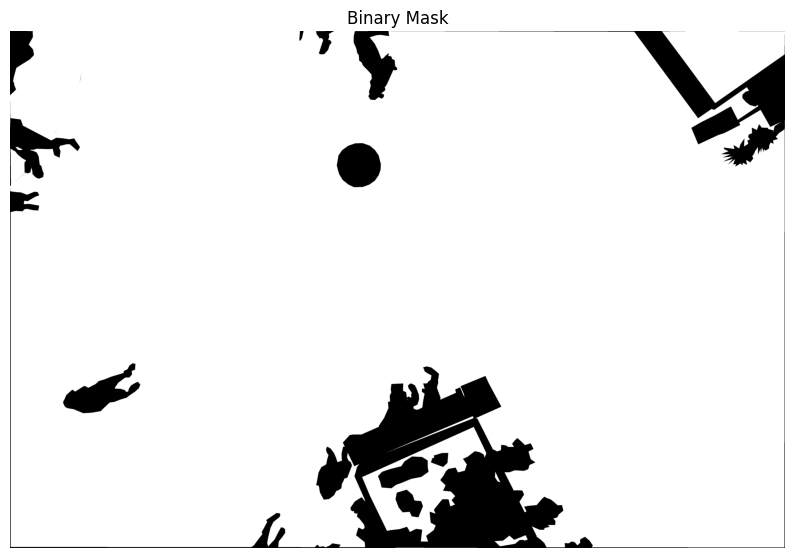

' 1 (white) → SAFE areas (landing allowed)\n0 (black) → UNSAFE areas (no landing) '

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Mask")
plt.axis("off")
plt.show()

""" 1 (white) → SAFE areas (landing allowed)
0 (black) → UNSAFE areas (no landing) """

In [ ]:
images = sorted(os.listdir(INPUT_IMG_DIR))
masks = sorted(os.listdir(INPUT_MASK_DIR))

print("Images:", len(images))
print("Masks:", len(masks))

Images: 400
Masks: 400


In [ ]:
for i in range(5):
    print(images[i], " ↔ ", masks[i])

000.jpg  ↔  000.png
001.jpg  ↔  001.png
002.jpg  ↔  002.png
003.jpg  ↔  003.png
004.jpg  ↔  004.png


In [ ]:
img_path = os.path.join(INPUT_IMG_DIR, images[0])
mask_path = os.path.join(INPUT_MASK_DIR, masks[0])

print(images[0])
print(masks[0])

000.jpg
000.png


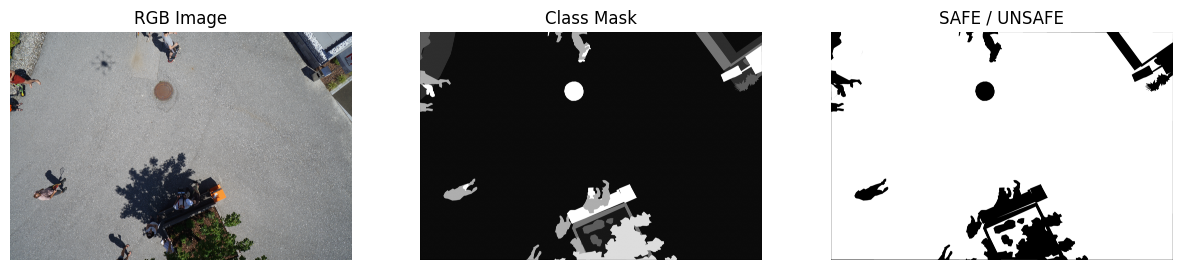

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image_name = sorted(os.listdir(INPUT_IMG_DIR))[0]
mask_name = sorted(os.listdir(INPUT_MASK_DIR))[0]

image_path = os.path.join(INPUT_IMG_DIR, image_name)
mask_path = os.path.join(INPUT_MASK_DIR, mask_name)


image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
SAFE_CLASSES = [1, 2, 3, 4]

binary_mask = np.isin(mask, SAFE_CLASSES).astype(np.uint8)



plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mask, cmap="gray")
plt.title("Class Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(binary_mask, cmap="gray")
plt.title("SAFE / UNSAFE")
plt.axis("off")

plt.show()

# Install requirements

In [ ]:
pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 8.8 MB/s eta 0:00:00


In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 19.5 MB/s eta 0:00:00


In [ ]:
import os, random, warnings
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from sklearn.model_selection import train_test_split
from torchmetrics.classification import (
    BinaryPrecision, BinaryRecall, BinaryF1Score
)
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# REPRODUCIBILITY

In [ ]:

# ==============================================================================
# 0.  REPRODUCIBILITY  — fix every RNG so results are stable across runs
# ==============================================================================
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Makes cuDNN deterministic (slight speed trade-off — worth it for research)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False   # set True only for fixed-size inputs in production

set_seed()


# Variables defining

In [ ]:
INPUT_IMG_DIR = "./data/dataset/semantic_drone_dataset/original_images"
INPUT_MASK_DIR = "./data/dataset/semantic_drone_dataset/label_images_semantic"
CHECKPOINT_DIR = "/content/drive/MyDrive"

In [ ]:
# ── Image ──────────────────────────────────────────────────────────────────────
IMG_SIZE    = 320
IN_CHANNELS = 3

# ── Training ───────────────────────────────────────────────────────────────────
EPOCHS         = 150
BATCH_SIZE     = 8
LEARNING_RATE  = 3e-4
WEIGHT_DECAY   = 1e-4
MAX_GRAD_NORM  = 1.0

# ── Scheduler & early stop ─────────────────────────────────────────────────────
PATIENCE_ES    = 15
PATIENCE_LR    = 5

# ── ImageNet stats (correct for pretrained encoders) ───────────────────────────
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

In [ ]:
# ── Device ─────────────────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️  Device: {DEVICE}")

🖥️  Device: cuda


# Data Preprocessing

### Data spliting

In [ ]:
# ==============================================================================
# 2.  DATA SPLIT  — stratification not applicable for segmentation, so random
# ==============================================================================
images = sorted(os.listdir(INPUT_IMG_DIR))
masks  = sorted(os.listdir(INPUT_MASK_DIR))

assert len(images) == len(masks), "⚠️  Image / mask count mismatch!"

# 70 / 15 / 15 split
train_imgs, temp_imgs, train_masks, temp_masks = train_test_split(
    images, masks, test_size=0.30, random_state=SEED
)
val_imgs, test_imgs, val_masks, test_masks = train_test_split(
    temp_imgs, temp_masks, test_size=0.50, random_state=SEED
)

print(f"📂 Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")


📂 Train: 280 | Val: 60 | Test: 60


### Data Augmentation

In [ ]:
# ==============================================================================
# 3.  AUGMENTATION PIPELINE
#     FIX: Use IMAGENET mean/std, not (0,0,0)/(1,1,1).
#          Raw-[0,1] normalization breaks pretrained encoder expectations.
# ==============================================================================
train_transform = A.Compose([
    # ── Resize ──────────────────────────────────────────────────────────────
    A.Resize(IMG_SIZE, IMG_SIZE),

    # ── Geometric (aerial / drone specific) ─────────────────────────────────
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.5),           # ← added: top-down views rotate 90° freely

    A.ShiftScaleRotate(
        shift_limit=0.1,
        scale_limit=0.2,
        rotate_limit=30,
        border_mode=cv2.BORDER_REFLECT_101,   # FIX: REFLECT > black border (0)
        p=0.7
    ),
    A.Perspective(scale=(0.04, 0.08), p=0.3),

    # ── Photometric ─────────────────────────────────────────────────────────
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.6),
    A.HueSaturationValue(hue_shift_limit=15, sat_shift_limit=30, val_shift_limit=20, p=0.4),
    A.CLAHE(clip_limit=4.0, p=0.3),    # ← added: enhances edge / texture visibility
    A.Sharpen(p=0.2),                  # ← added: combats aerial blur

    # ── Blur / Noise ────────────────────────────────────────────────────────
    A.OneOf([                          # ← use OneOf to avoid stacking blurs
        A.GaussianBlur(blur_limit=(3, 5)),
        A.MotionBlur(blur_limit=5),
        A.MedianBlur(blur_limit=3),
    ], p=0.3),
    A.GaussNoise(var_limit=(10.0, 40.0), p=0.3),

    # ── Weather simulation ───────────────────────────────────────────────────
    A.RandomShadow(num_shadows_lower=1, num_shadows_upper=2, p=0.3),
    A.RandomFog(fog_coef_lower=0.1, fog_coef_upper=0.3, p=0.2),
    A.RandomSunFlare(flare_roi=(0, 0, 1, 0.5), p=0.1),   # ← added: sun glare

    # ── Regularization via cutout ────────────────────────────────────────────
    A.CoarseDropout(                   # ← added: forces model to be robust to occlusion
        max_holes=8, max_height=32, max_width=32,
        min_holes=1, fill_value=0, mask_fill_value=0, p=0.3
    ),

    # ── Normalize with ImageNet stats (CRITICAL FIX) ─────────────────────────
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),   # FIX applied here too
    ToTensorV2(),
])


### Dataset class

In [ ]:
# ==============================================================================
# 4.  DATASET
# ==============================================================================
class DroneDataset(Dataset):
    """Binary segmentation: SAFE (1) vs UNSAFE (0) landing zones."""

    SAFE_CLASSES = SAFE_CLASSES

    def __init__(self, img_list, mask_list, img_dir, mask_dir, transform=None):
        self.img_list  = img_list
        self.mask_list = mask_list
        self.img_dir   = img_dir
        self.mask_dir  = mask_dir
        self.transform = transform

    def __len__(self):
        return len(self.img_list)

    def __getitem__(self, idx):
        img_path  = os.path.join(self.img_dir,  self.img_list[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_list[idx])

        # ── Load image ──────────────────────────────────────────────────────
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Image not found: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # ── Load mask ───────────────────────────────────────────────────────
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise FileNotFoundError(f"Mask not found: {mask_path}")

        # Binary: 1.0 = SAFE, 0.0 = UNSAFE
        mask = np.isin(mask, self.SAFE_CLASSES).astype(np.float32)

        # ── Augment ─────────────────────────────────────────────────────────
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask  = augmented["mask"]

        return image, mask.unsqueeze(0)   # mask → (1, H, W)

### Data Loaders

In [ ]:
# ==============================================================================
# 5.  DATA LOADERS
#     FIX: pin_memory + num_workers for faster GPU feeding
# ==============================================================================
_pin = DEVICE.type == "cuda"

train_dataset = DroneDataset(train_imgs, train_masks, INPUT_IMG_DIR, INPUT_MASK_DIR, train_transform)
val_dataset   = DroneDataset(val_imgs,   val_masks,   INPUT_IMG_DIR, INPUT_MASK_DIR, val_transform)
test_dataset  = DroneDataset(test_imgs,  test_masks,  INPUT_IMG_DIR, INPUT_MASK_DIR, val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=_pin, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=_pin)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=_pin)


# Model U-NET

In [ ]:
# ==============================================================================
# 6.  MODEL
#     UPGRADE: EfficientNet-B4 encoder (ImageNet pretrained)
#              → significantly better feature extraction than ResNet-34
#              → same U-Net decoder, same binary output
#     ALTERNATIVE encoders to try (swap encoder_name):
#       "efficientnet-b2"  → faster, slightly lower accuracy
#       "resnet50"         → good if GPU memory is tight
#       "mit_b2"           → transformer-based, excellent for aerial
# ==============================================================================
model = smp.Unet(
    encoder_name    = "efficientnet-b0",
    encoder_weights = "imagenet" ,   # IMPORTANT
    in_channels     = IN_CHANNELS,
    classes         = 1,
    activation      = None,
    decoder_use_batchnorm = True,
)
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"🔢 Trainable parameters: {total_params:,}")

🔢 Trainable parameters: 6,251,469


# Loss Fucntion

In [ ]:
# ==============================================================================
# 7.  LOSS FUNCTION
#     UPGRADE: Tversky loss replaces plain Dice for better recall on small
#              safe zones (alpha > beta penalises false-negatives harder).
#     Combined: BCE (pixel-level) + Tversky (structural)
# ==============================================================================
bce_loss    = nn.BCEWithLogitsLoss()
tversky_loss = smp.losses.TverskyLoss(
    mode="binary",
    alpha=0.3,   # weight on False Positives  (lower → tolerate FP more)
    beta=0.7,    # weight on False Negatives  (higher → penalise missed safe zones)
    smooth=1e-6
)

def loss_fn(pred, target):
    """50 % BCE + 50 % Tversky — balances pixel accuracy & structural overlap."""
    return 0.5 * bce_loss(pred, target) + 0.5 * tversky_loss(pred, target)

# Optimizer

In [ ]:
# ==============================================================================
# 8.  OPTIMIZER  — AdamW (same as before, slightly tuned)
# ==============================================================================
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    eps=1e-8
)


# Scheduler

In [ ]:
# ==============================================================================
# 9.  LEARNING-RATE SCHEDULER
#     UPGRADE: CosineAnnealingWarmRestarts → smooth LR cycle, avoids
#              premature plateau; much better than ReduceLROnPlateau alone.
#     We keep ReduceLROnPlateau as a safety net below.
# ==============================================================================
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=20,       # restart every 20 epochs
    T_mult=1,
    eta_min=1e-6
)

# Optional safety-net plateau scheduler (applied on top):
plateau_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=PATIENCE_LR, factor=0.5, min_lr=1e-7
)



# Metrics

In [ ]:
# ==============================================================================
# 10.  METRICS
# ==============================================================================
def iou_score(pred, target, threshold=0.5):
    pred = (torch.sigmoid(pred) > threshold).float()
    inter = (pred * target).sum(dim=(1, 2, 3))
    union = (pred + target).sum(dim=(1, 2, 3)) - inter
    return ((inter + 1e-6) / (union + 1e-6)).mean()

def dice_score(pred, target, threshold=0.5):
    pred  = (torch.sigmoid(pred) > threshold).float()
    inter = (pred * target).sum(dim=(1, 2, 3))
    denom = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return ((2 * inter + 1e-6) / (denom + 1e-6)).mean()

# torchmetrics objects (accumulate across batches, accurate)
_mk = lambda cls: cls(threshold=0.5).to(DEVICE)
train_precision_m = _mk(BinaryPrecision)
train_recall_m    = _mk(BinaryRecall)
train_f1_m        = _mk(BinaryF1Score)
val_precision_m   = _mk(BinaryPrecision)
val_recall_m      = _mk(BinaryRecall)
val_f1_m          = _mk(BinaryF1Score)



# Early stopping

In [ ]:
# ==============================================================================
# 11.  EARLY STOPPING  (unchanged logic, cleaned up)
# ==============================================================================
class EarlyStopping:
    def __init__(self, patience: int = PATIENCE_ES, min_delta: float = 1e-4):
        self.patience   = patience
        self.min_delta  = min_delta
        self.counter    = 0
        self.best_loss  = float("inf")

    def step(self, val_loss: float) -> bool:
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter   = 0
            return False
        self.counter += 1
        return self.counter >= self.patience

early_stopper = EarlyStopping()

In [ ]:
# ==============================================================================
# 12.  MIXED PRECISION  — AMP for free speed on any NVIDIA GPU
# ==============================================================================
use_amp  = DEVICE.type == "cuda"
scaler   = torch.cuda.amp.GradScaler(enabled=use_amp)

# Training Loop

In [ ]:

# ==============================================================================
# 13.  TRAINING LOOP
# ==============================================================================
history = {k: [] for k in [
    "train_loss", "val_loss",
    "train_iou",  "val_iou",
    "train_dice", "val_dice",
    "train_prec", "val_prec",
    "train_rec",  "val_rec",
    "train_f1",   "val_f1",
    "lr",
]}

ALL_CKPT_DIR = os.path.join(CHECKPOINT_DIR, "all_epochs")
os.makedirs(ALL_CKPT_DIR, exist_ok=True)

best_val_loss = float("inf")
best_epoch    = 1

for epoch in range(1, EPOCHS + 1):

    # ── Reset accumulators ──────────────────────────────────────────────────
    for m in [train_precision_m, train_recall_m, train_f1_m,
              val_precision_m,   val_recall_m,   val_f1_m]:
        m.reset()

    # ════════════════════════════════════════════════════════════════════════
    # TRAIN
    # ════════════════════════════════════════════════════════════════════════
    model.train()
    t_loss = t_iou = t_dice = 0.0

    for images, masks in train_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)   # faster than zero_grad()

        with torch.cuda.amp.autocast(enabled=use_amp):
            outputs = model(images)
            loss    = loss_fn(outputs, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            t_loss += loss.item()
            t_iou  += iou_score(outputs, masks).item()
            t_dice += dice_score(outputs, masks).item()
            probs   = torch.sigmoid(outputs)
            train_precision_m.update(probs, masks.int())
            train_recall_m.update(probs, masks.int())
            train_f1_m.update(probs, masks.int())

    n = len(train_loader)
    t_loss /= n;  t_iou /= n;  t_dice /= n
    t_prec = train_precision_m.compute().item()
    t_rec  = train_recall_m.compute().item()
    t_f1   = train_f1_m.compute().item()

    # ════════════════════════════════════════════════════════════════════════
    # VALIDATION
    # ════════════════════════════════════════════════════════════════════════
    model.eval()
    v_loss = v_iou = v_dice = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)

            with torch.cuda.amp.autocast(enabled=use_amp):
                outputs = model(images)
                loss    = loss_fn(outputs, masks)

            v_loss += loss.item()
            v_iou  += iou_score(outputs, masks).item()
            v_dice += dice_score(outputs, masks).item()
            probs   = torch.sigmoid(outputs)
            val_precision_m.update(probs, masks.int())
            val_recall_m.update(probs, masks.int())
            val_f1_m.update(probs, masks.int())

    n = len(val_loader)
    v_loss /= n;  v_iou /= n;  v_dice /= n
    v_prec = val_precision_m.compute().item()
    v_rec  = val_recall_m.compute().item()
    v_f1   = val_f1_m.compute().item()

    # ── Schedulers ──────────────────────────────────────────────────────────
    scheduler.step(epoch - 1 + 0)          # cosine warm restarts
    plateau_scheduler.step(v_loss)          # plateau safety net
    current_lr = optimizer.param_groups[0]["lr"]

    # ── Log ─────────────────────────────────────────────────────────────────
    history["train_loss"].append(t_loss);  history["val_loss"].append(v_loss)
    history["train_iou"].append(t_iou);    history["val_iou"].append(v_iou)
    history["train_dice"].append(t_dice);  history["val_dice"].append(v_dice)
    history["train_prec"].append(t_prec);  history["val_prec"].append(v_prec)
    history["train_rec"].append(t_rec);    history["val_rec"].append(v_rec)
    history["train_f1"].append(t_f1);      history["val_f1"].append(v_f1)
    history["lr"].append(current_lr)

    print(f"\n --- Epoch [{epoch:03d}/{EPOCHS}]  LR: {current_lr:.2e}")
    print(f"   Loss  → Train: {t_loss:.4f}  Val: {v_loss:.4f}")
    print(f"   IoU   → Train: {t_iou:.4f}  Val: {v_iou:.4f}")
    print(f"   Dice  → Train: {t_dice:.4f}  Val: {v_dice:.4f}")
    print(f"   F1    → Train: {t_f1:.4f}  Val: {v_f1:.4f}")
    print(f"   Prec  → Train: {t_prec:.4f}  Val: {v_prec:.4f}")
    print(f"   Rec   → Train: {t_rec:.4f}  Val: {v_rec:.4f}")

    # ── Save EVERY epoch ─────────────────────────────────────────────────────
    epoch_checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "plateau_scheduler_state_dict": plateau_scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "val_loss": v_loss,
        "early_stopping_counter": early_stopper.counter,
        "history" : history,
    }

    epoch_ckpt_path = os.path.join(
        ALL_CKPT_DIR,
        f"epoch_{epoch:03d}.pth"
    )

    torch.save(epoch_checkpoint, epoch_ckpt_path)

    # ── Save best checkpoint ─────────────────────────────────────────────────
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        best_epoch    = epoch
        checkpoint = {
            "epoch"               : epoch,
            "model_state_dict"    : model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict"   : scaler.state_dict(),
            "plateau_scheduler_state_dict": plateau_scheduler.state_dict(),
            "early_stopping_counter": early_stopper.counter,
            "early_stopping_best_loss": early_stopper.best_loss,
            "best_val_loss"       : best_val_loss,
            "history"             : history,
            "config": {
                "IMG_SIZE"      : IMG_SIZE,
                "SAFE_CLASSES"  : SAFE_CLASSES,
                "IMAGENET_MEAN" : IMAGENET_MEAN,
                "IMAGENET_STD"  : IMAGENET_STD,
                "encoder": "efficientnet-b0",
            }
        }
        ckpt_path = os.path.join(CHECKPOINT_DIR, "best_checkpoint_efficientnetb0.pth")
        torch.save(checkpoint, ckpt_path)
        print(f"   ✅ Best model saved → epoch {epoch} (Val Loss: {best_val_loss:.4f})")

    # ── Early stopping ───────────────────────────────────────────────────────
    if early_stopper.step(v_loss):
        print(f"\n⛔ Early stopping at epoch {epoch} (no improvement for {PATIENCE_ES} epochs)")
        break


print(f"\n{'='*50}")
print(f"✅ TRAINING COMPLETE")
print(f"   Best Epoch    : {best_epoch}")
print(f"   Best Val Loss : {best_val_loss:.4f}")
print(f"{'='*50}")


 --- Epoch [001/60]  LR: 3.00e-04
   Loss  → Train: 0.4617  Val: 0.3464
   IoU   → Train: 0.6227  Val: 0.7151
   Dice  → Train: 0.7492  Val: 0.8237
   F1    → Train: 0.7784  Val: 0.8416
   Prec  → Train: 0.7526  Val: 0.7820
   Rec   → Train: 0.8060  Val: 0.9111
   ✅ Best model saved → epoch 1 (Val Loss: 0.3464)

 --- Epoch [002/60]  LR: 2.98e-04
   Loss  → Train: 0.3702  Val: 0.2820
   IoU   → Train: 0.7033  Val: 0.7649
   Dice  → Train: 0.8138  Val: 0.8603
   F1    → Train: 0.8336  Val: 0.8726
   Prec  → Train: 0.7761  Val: 0.7988
   Rec   → Train: 0.9003  Val: 0.9614
   ✅ Best model saved → epoch 2 (Val Loss: 0.2820)

 --- Epoch [003/60]  LR: 2.93e-04
   Loss  → Train: 0.3398  Val: 0.2759
   IoU   → Train: 0.7209  Val: 0.7695
   Dice  → Train: 0.8258  Val: 0.8642
   F1    → Train: 0.8456  Val: 0.8765
   Prec  → Train: 0.7967  Val: 0.8144
   Rec   → Train: 0.9009  Val: 0.9487
   ✅ Best model saved → epoch 3 (Val Loss: 0.2759)

 --- Epoch [004/60]  LR: 2.84e-04
   Loss  → Train: 0.312

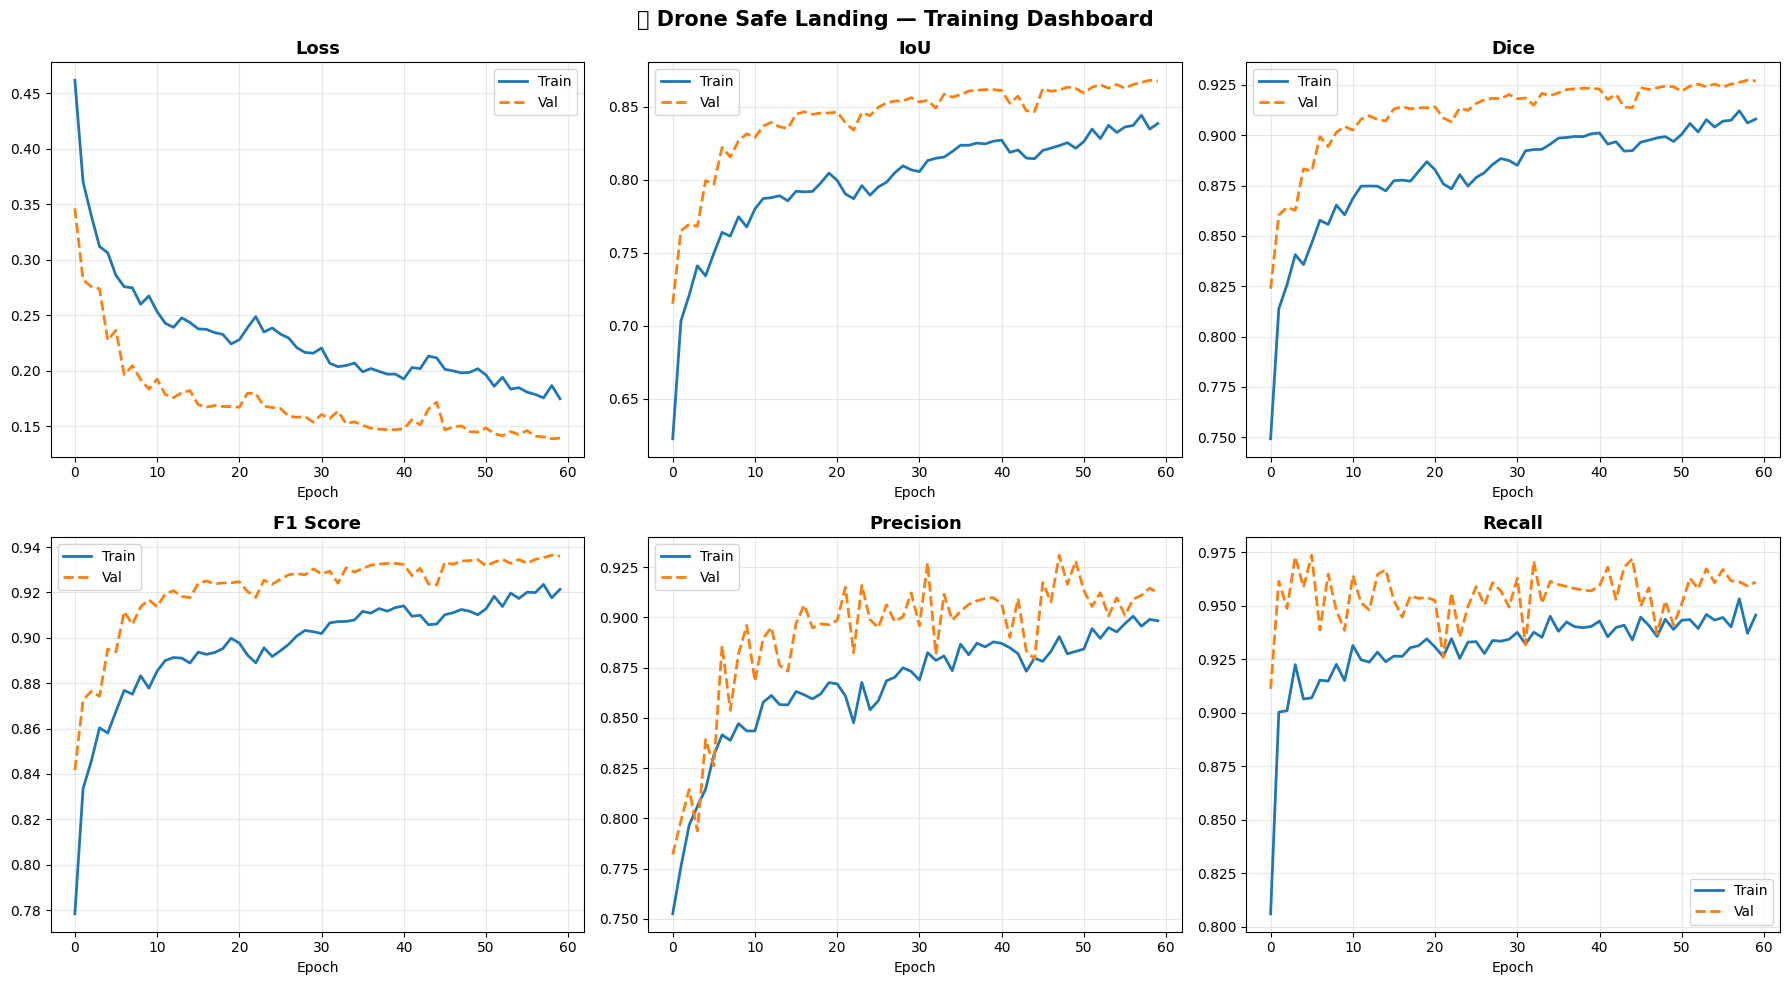

📈 Curves saved → training_curves.png


In [ ]:
# ==============================================================================
# 15.  TRAINING CURVES  — 6-panel dashboard
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

panels = [
    ("Loss",      "train_loss", "val_loss"),
    ("IoU",       "train_iou",  "val_iou"),
    ("Dice",      "train_dice", "val_dice"),
    ("F1 Score",  "train_f1",   "val_f1"),
    ("Precision", "train_prec", "val_prec"),
    ("Recall",    "train_rec",  "val_rec"),
]

for ax, (title, tr_key, va_key) in zip(axes, panels):
    ax.plot(history[tr_key], label="Train", linewidth=2)
    ax.plot(history[va_key], label="Val",   linewidth=2, linestyle="--")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("🚁 Drone Safe Landing — Training Dashboard", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("📈 Curves saved → training_curves.png")


# Resuming Training


In [ ]:
ckpt_path = "/content/drive/MyDrive/all_epochs/epoch_075.pth"

checkpoint = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

model.load_state_dict(checkpoint["model_state_dict"])

optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

plateau_scheduler.load_state_dict(
        checkpoint["plateau_scheduler_state_dict"]
    )

scaler.load_state_dict(checkpoint["scaler_state_dict"])

history = checkpoint["history"]

best_val_loss = min(history["val_loss"])
best_epoch = np.argmin(history["val_loss"]) + 1
early_stopper.counter = checkpoint["early_stopping_counter"]
early_stopper.best_loss = best_val_loss

start_epoch = checkpoint["epoch"] + 1

print(f"✅ Resuming from epoch {checkpoint['epoch']} ,{best_val_loss} , {best_epoch} ")

✅ Resuming from epoch 75 ,0.13290885370224714 , 75 


In [ ]:

# ==============================================================================
# 13.  TRAINING LOOP
# ==============================================================================


ALL_CKPT_DIR = os.path.join(CHECKPOINT_DIR, "all_epochs")
os.makedirs(ALL_CKPT_DIR, exist_ok=True)


for epoch in range(start_epoch, EPOCHS + 1):

    # ── Reset accumulators ──────────────────────────────────────────────────
    for m in [train_precision_m, train_recall_m, train_f1_m,
              val_precision_m,   val_recall_m,   val_f1_m]:
        m.reset()

    # ════════════════════════════════════════════════════════════════════════
    # TRAIN
    # ════════════════════════════════════════════════════════════════════════
    model.train()
    t_loss = t_iou = t_dice = 0.0

    for images, masks in train_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)   # faster than zero_grad()

        with torch.cuda.amp.autocast(enabled=use_amp):
            outputs = model(images)
            loss    = loss_fn(outputs, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            t_loss += loss.item()
            t_iou  += iou_score(outputs, masks).item()
            t_dice += dice_score(outputs, masks).item()
            probs   = torch.sigmoid(outputs)
            train_precision_m.update(probs, masks.int())
            train_recall_m.update(probs, masks.int())
            train_f1_m.update(probs, masks.int())

    n = len(train_loader)
    t_loss /= n;  t_iou /= n;  t_dice /= n
    t_prec = train_precision_m.compute().item()
    t_rec  = train_recall_m.compute().item()
    t_f1   = train_f1_m.compute().item()

    # ════════════════════════════════════════════════════════════════════════
    # VALIDATION
    # ════════════════════════════════════════════════════════════════════════
    model.eval()
    v_loss = v_iou = v_dice = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)

            with torch.cuda.amp.autocast(enabled=use_amp):
                outputs = model(images)
                loss    = loss_fn(outputs, masks)

            v_loss += loss.item()
            v_iou  += iou_score(outputs, masks).item()
            v_dice += dice_score(outputs, masks).item()
            probs   = torch.sigmoid(outputs)
            val_precision_m.update(probs, masks.int())
            val_recall_m.update(probs, masks.int())
            val_f1_m.update(probs, masks.int())

    n = len(val_loader)
    v_loss /= n;  v_iou /= n;  v_dice /= n
    v_prec = val_precision_m.compute().item()
    v_rec  = val_recall_m.compute().item()
    v_f1   = val_f1_m.compute().item()

    # ── Schedulers ──────────────────────────────────────────────────────────
    scheduler.step(epoch - 1 + 0)          # cosine warm restarts
    plateau_scheduler.step(v_loss)          # plateau safety net
    current_lr = optimizer.param_groups[0]["lr"]

    # ── Log ─────────────────────────────────────────────────────────────────
    history["train_loss"].append(t_loss);  history["val_loss"].append(v_loss)
    history["train_iou"].append(t_iou);    history["val_iou"].append(v_iou)
    history["train_dice"].append(t_dice);  history["val_dice"].append(v_dice)
    history["train_prec"].append(t_prec);  history["val_prec"].append(v_prec)
    history["train_rec"].append(t_rec);    history["val_rec"].append(v_rec)
    history["train_f1"].append(t_f1);      history["val_f1"].append(v_f1)
    history["lr"].append(current_lr)

    print(f"\n --- Epoch [{epoch:03d}/{EPOCHS}]  LR: {current_lr:.2e}")
    print(f"   Loss  → Train: {t_loss:.4f}  Val: {v_loss:.4f}")
    print(f"   IoU   → Train: {t_iou:.4f}  Val: {v_iou:.4f}")
    print(f"   Dice  → Train: {t_dice:.4f}  Val: {v_dice:.4f}")
    print(f"   F1    → Train: {t_f1:.4f}  Val: {v_f1:.4f}")
    print(f"   Prec  → Train: {t_prec:.4f}  Val: {v_prec:.4f}")
    print(f"   Rec   → Train: {t_rec:.4f}  Val: {v_rec:.4f}")

    # ── Save EVERY epoch ─────────────────────────────────────────────────────
    epoch_checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "plateau_scheduler_state_dict": plateau_scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "val_loss": v_loss,
        "early_stopping_counter": early_stopper.counter,
        "early_stopping_best_loss": early_stopper.best_loss,
        "history" : history,
    }

    epoch_ckpt_path = os.path.join(
        ALL_CKPT_DIR,
        f"epoch_{epoch:03d}.pth"
    )

    torch.save(epoch_checkpoint, epoch_ckpt_path)

    # ── Save best checkpoint ─────────────────────────────────────────────────
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        best_epoch    = epoch
        checkpoint = {
            "epoch"               : epoch,
            "model_state_dict"    : model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict"   : scaler.state_dict(),
            "plateau_scheduler_state_dict": plateau_scheduler.state_dict(),
            "early_stopping_counter": early_stopper.counter,
            "early_stopping_best_loss": early_stopper.best_loss,
            "best_val_loss"       : best_val_loss,
            "history"             : history,
            "config": {
                "IMG_SIZE"      : IMG_SIZE,
                "SAFE_CLASSES"  : SAFE_CLASSES,
                "IMAGENET_MEAN" : IMAGENET_MEAN,
                "IMAGENET_STD"  : IMAGENET_STD,
                "encoder": "efficientnet-b0",
            }
        }
        ckpt_path = os.path.join(CHECKPOINT_DIR, "best_checkpoint_efficientnetb0.pth")
        torch.save(checkpoint, ckpt_path)
        print(f"   ✅ Best model saved → epoch {epoch} (Val Loss: {best_val_loss:.4f})")

    # ── Early stopping ───────────────────────────────────────────────────────
    if early_stopper.step(v_loss):
        print(f"\n⛔ Early stopping at epoch {epoch} (no improvement for {PATIENCE_ES} epochs)")
        break


print(f"\n{'='*50}")
print(f"✅ TRAINING COMPLETE")
print(f"   Best Epoch    : {best_epoch}")
print(f"   Best Val Loss : {best_val_loss:.4f}")
print(f"{'='*50}")


 --- Epoch [076/150]  LR: 4.48e-05
   Loss  → Train: 0.1812  Val: 0.1307
   IoU   → Train: 0.8362  Val: 0.8765
   Dice  → Train: 0.9061  Val: 0.9325
   F1    → Train: 0.9194  Val: 0.9411
   Prec  → Train: 0.8952  Val: 0.9280
   Rec   → Train: 0.9449  Val: 0.9546
   ✅ Best model saved → epoch 76 (Val Loss: 0.1307)

 --- Epoch [077/150]  LR: 2.96e-05
   Loss  → Train: 0.1791  Val: 0.1305
   IoU   → Train: 0.8400  Val: 0.8757
   Dice  → Train: 0.9088  Val: 0.9319
   F1    → Train: 0.9203  Val: 0.9404
   Prec  → Train: 0.8929  Val: 0.9202
   Rec   → Train: 0.9494  Val: 0.9615
   ✅ Best model saved → epoch 77 (Val Loss: 0.1305)

 --- Epoch [078/150]  LR: 1.73e-05
   Loss  → Train: 0.1798  Val: 0.1299
   IoU   → Train: 0.8408  Val: 0.8764
   Dice  → Train: 0.9090  Val: 0.9324
   F1    → Train: 0.9216  Val: 0.9409
   Prec  → Train: 0.8963  Val: 0.9231
   Rec   → Train: 0.9485  Val: 0.9594
   ✅ Best model saved → epoch 78 (Val Loss: 0.1299)

 --- Epoch [079/150]  LR: 8.32e-06
   Loss  → Train

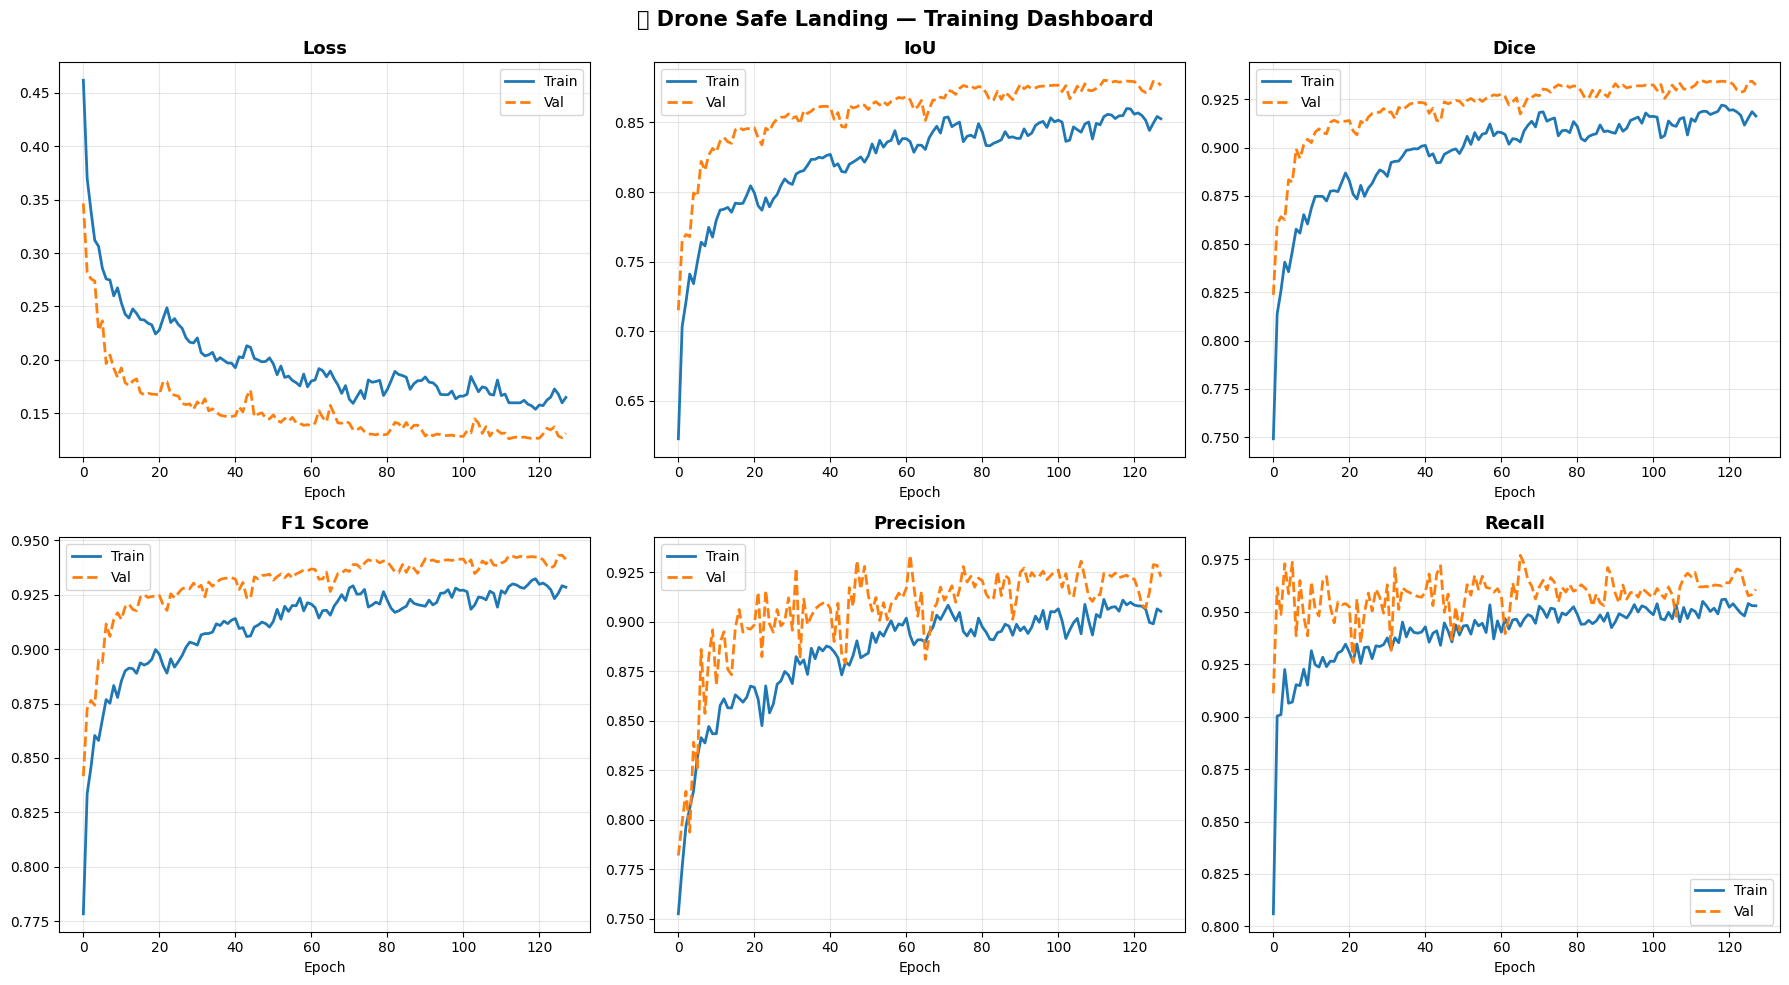

📈 Curves saved → training_curves.png


In [ ]:
# ==============================================================================
# 15.  TRAINING CURVES  — 6-panel dashboard
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

panels = [
    ("Loss",      "train_loss", "val_loss"),
    ("IoU",       "train_iou",  "val_iou"),
    ("Dice",      "train_dice", "val_dice"),
    ("F1 Score",  "train_f1",   "val_f1"),
    ("Precision", "train_prec", "val_prec"),
    ("Recall",    "train_rec",  "val_rec"),
]

for ax, (title, tr_key, va_key) in zip(axes, panels):
    ax.plot(history[tr_key], label="Train", linewidth=2)
    ax.plot(history[va_key], label="Val",   linewidth=2, linestyle="--")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("🚁 Drone Safe Landing — Training Dashboard", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("📈 Curves saved → training_curves.png")


# LOADING MODEL

In [ ]:
# ==============================================================================
# 14.  TEST EVALUATION  — run on held-out test set with best weights
# ==============================================================================
print("\n🧪 Evaluating on TEST set …")

ckpt = torch.load(os.path.join(CHECKPOINT_DIR, "best_checkpoint_efficientnetb0.pth"),
                        map_location=DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

test_prec_m = _mk(BinaryPrecision)
test_rec_m  = _mk(BinaryRecall)
test_f1_m   = _mk(BinaryF1Score)

te_loss = te_iou = te_dice = 0.0

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        outputs = model(images)
        te_loss  += loss_fn(outputs, masks).item()
        te_iou   += iou_score(outputs, masks).item()
        te_dice  += dice_score(outputs, masks).item()
        probs = torch.sigmoid(outputs)
        test_prec_m.update(probs, masks.int())
        test_rec_m.update(probs, masks.int())
        test_f1_m.update(probs, masks.int())

n = len(test_loader)
print(f"\n📊 TEST RESULTS")
print(f"   Loss      : {te_loss/n:.4f}")
print(f"   IoU       : {te_iou/n:.4f}")
print(f"   Dice      : {te_dice/n:.4f}")
print(f"   F1        : {test_f1_m.compute().item():.4f}")
print(f"   Precision : {test_prec_m.compute().item():.4f}")
print(f"   Recall    : {test_rec_m.compute().item():.4f}")


🧪 Evaluating on TEST set …

📊 TEST RESULTS
   Loss      : 0.1131
   IoU       : 0.8979
   Dice      : 0.9444
   F1        : 0.9504
   Precision : 0.9348
   Recall    : 0.9665


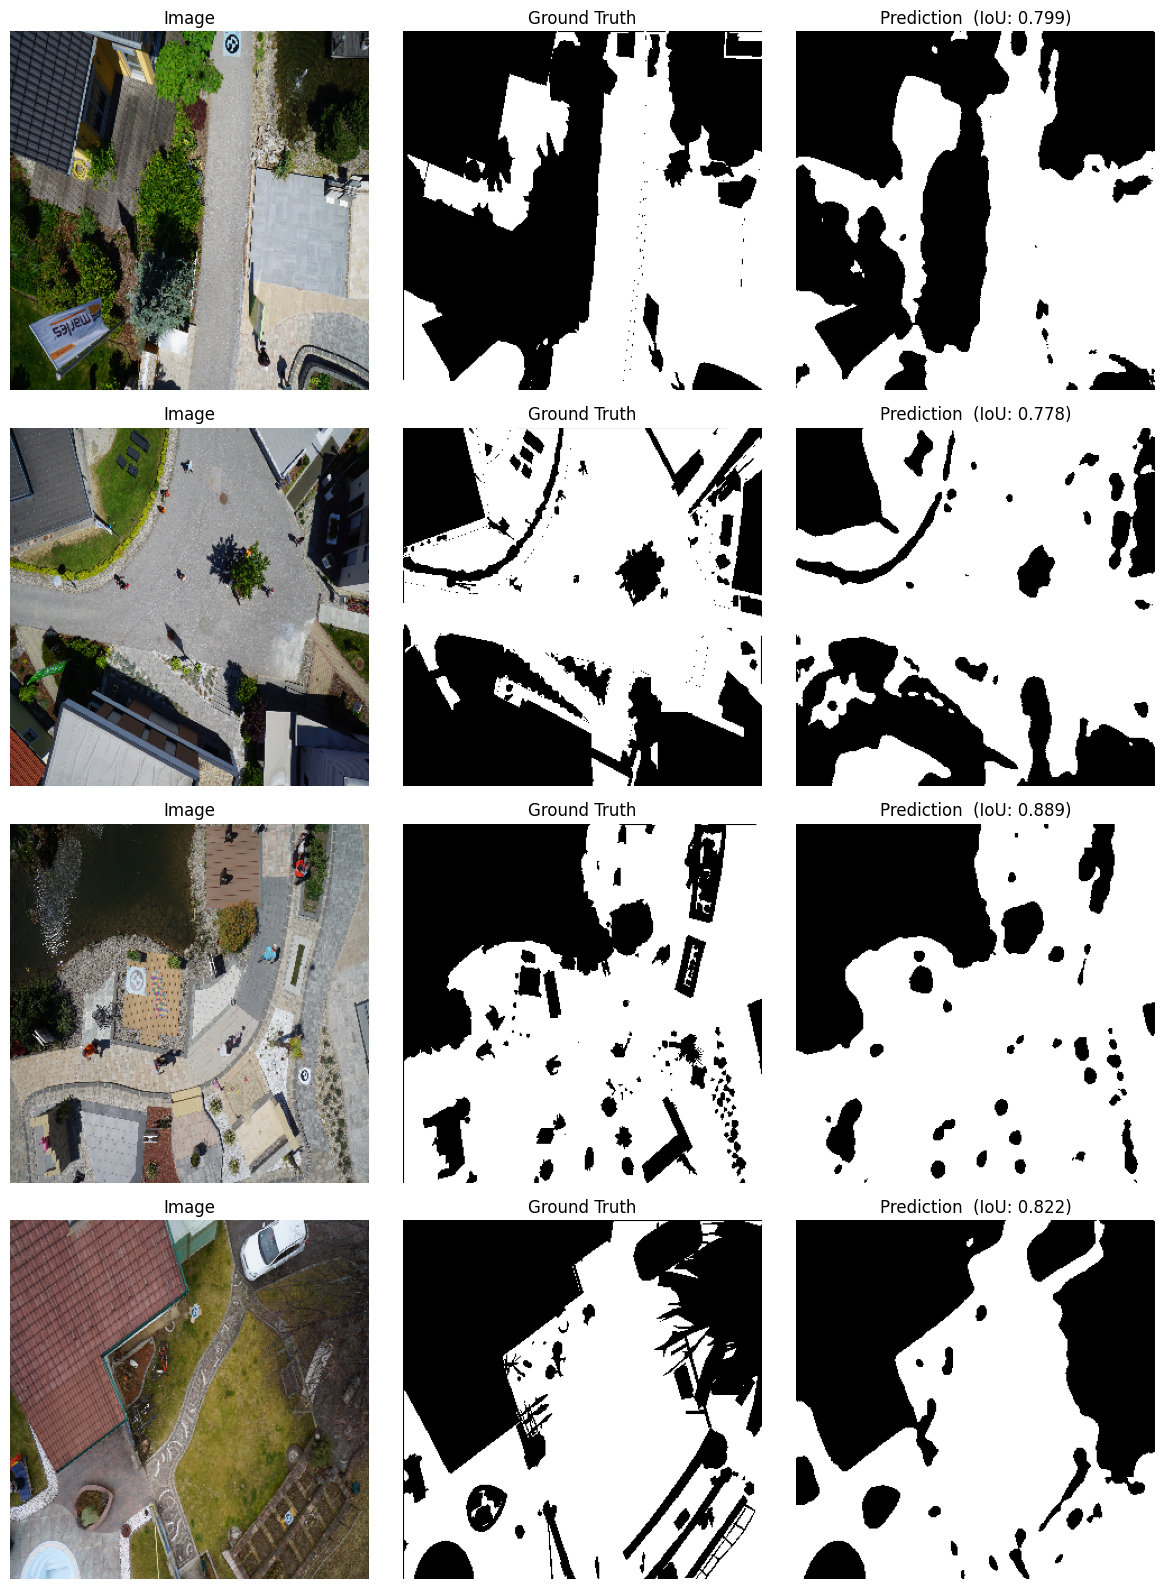

🖼️  Predictions saved → predictions.png


In [ ]:
# ==============================================================================
# 16.  VISUAL INFERENCE HELPER  — sanity-check on random val samples
# ==============================================================================
def visualize_predictions(model, dataset, n=4, threshold=0.5, save_path="predictions.png"):
    model.eval()
    indices = random.sample(range(len(dataset)), n)
    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
    if n == 1:
        axes = [axes]

    with torch.no_grad():
        for row, idx in enumerate(indices):
            img_t, mask_t = dataset[idx]
            pred = model(img_t.unsqueeze(0).to(DEVICE))
            pred_bin = (torch.sigmoid(pred) > threshold).float().squeeze().cpu().numpy()

            # Denormalize image for display
            mean = np.array(IMAGENET_MEAN)
            std  = np.array(IMAGENET_STD)
            img_np = img_t.permute(1, 2, 0).numpy()
            img_np = np.clip(img_np * std + mean, 0, 1)

            mask_np = mask_t.squeeze().numpy()

            iou_val = ((pred_bin * mask_np).sum() + 1e-6) / \
                      ((pred_bin + mask_np).sum() - (pred_bin * mask_np).sum() + 1e-6)

            axes[row][0].imshow(img_np);           axes[row][0].set_title("Image")
            axes[row][1].imshow(mask_np, cmap="gray"); axes[row][1].set_title("Ground Truth")
            axes[row][2].imshow(pred_bin, cmap="gray")
            axes[row][2].set_title(f"Prediction  (IoU: {iou_val:.3f})")

            for ax in axes[row]: ax.axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"🖼️  Predictions saved → {save_path}")

visualize_predictions(model, val_dataset, n=4)


# Detect valid area for landing (best area)

Selected image index : 38
Connected Components Found : 2

Filtering regions with MIN_AREA = 5000
Region 1 KEPT | Area=57549 px | BBox=(0,0,320,320) | Centroid=(163.5,197.3)
Region 2 REMOVED (area=520)

Valid Landing Zones: 1


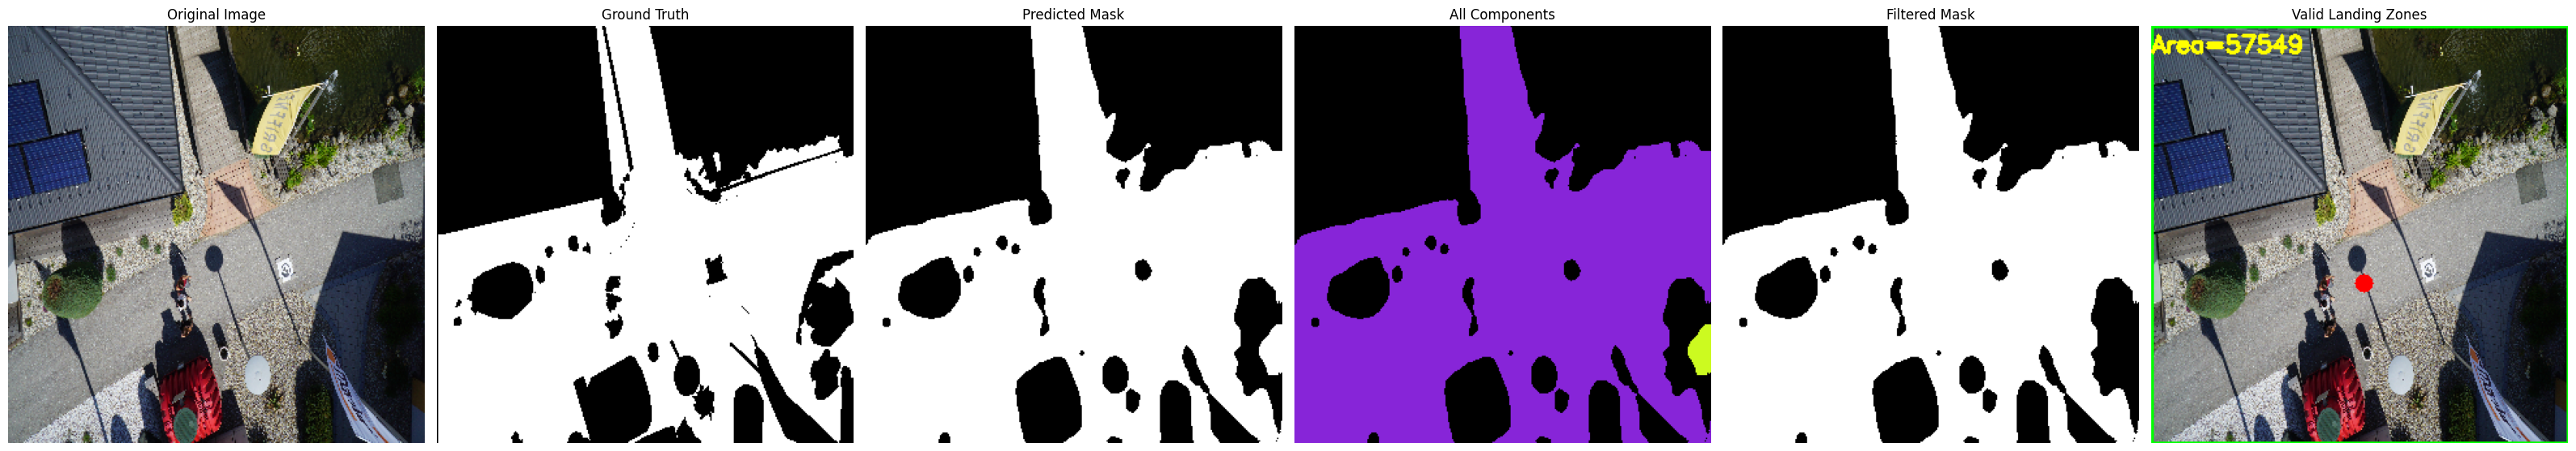

In [ ]:
import cv2
import torch
import random
import numpy as np
import matplotlib.pyplot as plt


# ==============================================================================
# RANDOM TEST IMAGE
# ==============================================================================

idx = np.random.choice(len(test_dataset))

image, mask = test_dataset[idx]

images = image.unsqueeze(0).to(DEVICE)
masks = mask.unsqueeze(0).to(DEVICE)

print("=" * 60)
print(f"Selected image index : {idx}")
print("=" * 60)

# ==============================================================================
# PREDICT
# ==============================================================================

with torch.no_grad():

    outputs = model(images)

    probs = torch.sigmoid(outputs)

    pred_mask = (probs[0] > 0.5).float()

pred_mask_np = pred_mask.squeeze().cpu().numpy().astype(np.uint8)

# ==============================================================================
# CONNECTED COMPONENTS
# ==============================================================================

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    pred_mask_np,
    connectivity=8
)

print("=" * 60)
print(f"Connected Components Found : {num_labels - 1}")
print("=" * 60)

# ==============================================================================
# COLORED COMPONENTS VISUALIZATION
# ==============================================================================

colored_labels = np.zeros(
    (labels.shape[0], labels.shape[1], 3),
    dtype=np.uint8
)

rng = np.random.default_rng(42)

for i in range(1, num_labels):

    color = rng.integers(
        0,
        255,
        size=3,
        dtype=np.uint8
    )

    colored_labels[labels == i] = color

# ==============================================================================
# FILTER BY AREA
# ==============================================================================

MIN_AREA = 5000

valid_regions = []

print("\n" + "=" * 60)
print(f"Filtering regions with MIN_AREA = {MIN_AREA}")
print("=" * 60)

for i in range(1, num_labels):

    area = stats[i, cv2.CC_STAT_AREA]

    if area < MIN_AREA:

        print(f"Region {i} REMOVED (area={area})")
        continue

    valid_regions.append(i)

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]

    cx, cy = centroids[i]

    print(
        f"Region {i} KEPT | "
        f"Area={area} px | "
        f"BBox=({x},{y},{w},{h}) | "
        f"Centroid=({cx:.1f},{cy:.1f})"
    )

print("\nValid Landing Zones:", len(valid_regions))

# ==============================================================================
# CREATE FILTERED MASK
# ==============================================================================

filtered_mask = np.zeros_like(pred_mask_np)

for region_id in valid_regions:

    filtered_mask[labels == region_id] = 1

# ==============================================================================
# PREPARE IMAGE
# ==============================================================================

img_np = images[0].cpu().permute(1, 2, 0).numpy()

mean = np.array(IMAGENET_MEAN)
std = np.array(IMAGENET_STD)

img_np = np.clip(img_np * std + mean, 0, 1)

# ==============================================================================
# ALL COMPONENTS VISUALIZATION
# ==============================================================================

all_components_vis = (img_np * 255).astype(np.uint8).copy()

for i in range(1, num_labels):

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]

    cx, cy = centroids[i]

    cv2.rectangle(
        all_components_vis,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.circle(
        all_components_vis,
        (int(cx), int(cy)),
        5,
        (255, 0, 0),
        -1
    )

# ==============================================================================
# FILTERED COMPONENTS VISUALIZATION
# ==============================================================================

filtered_vis = (img_np * 255).astype(np.uint8).copy()

for region_id in valid_regions:

    area = stats[region_id, cv2.CC_STAT_AREA]

    x = stats[region_id, cv2.CC_STAT_LEFT]
    y = stats[region_id, cv2.CC_STAT_TOP]
    w = stats[region_id, cv2.CC_STAT_WIDTH]
    h = stats[region_id, cv2.CC_STAT_HEIGHT]

    cx, cy = centroids[region_id]

    cv2.rectangle(
        filtered_vis,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.circle(
        filtered_vis,
        (int(cx), int(cy)),
        7,
        (255, 0, 0),
        -1
    )

    cv2.putText(
        filtered_vis,
        f"Area={area}",
        (x, max(20, y - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 255, 0),
        2
    )

# ==============================================================================
# DISPLAY
# ==============================================================================

fig, ax = plt.subplots(1, 6, figsize=(32, 6))

ax[0].imshow(img_np)
ax[0].set_title("Original Image")

ax[1].imshow(
    masks[0].squeeze().cpu().numpy(),
    cmap="gray"
)
ax[1].set_title("Ground Truth")

ax[2].imshow(
    pred_mask_np,
    cmap="gray"
)
ax[2].set_title("Predicted Mask")

ax[3].imshow(colored_labels)
ax[3].set_title("All Components")

ax[4].imshow(
    filtered_mask,
    cmap="gray"
)
ax[4].set_title("Filtered Mask")

ax[5].imshow(filtered_vis)
ax[5].set_title("Valid Landing Zones")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Guidance Drone Logic (Guidance module)

In [ ]:
import math

# ==============================================================================
# GUIDANCE CONTROLLER
# ==============================================================================

def guidance_controller(
    landing_x,
    landing_y,
    image_width,
    image_height,
    tolerance=10
):
    """
    Computes geometric guidance information.

    This module DOES NOT decide the flight state.
    It only computes the error between the drone image center
    and the landing target.

    Returns
    -------
    dict
    """

    # ------------------------------------------------------------------
    # Image Center
    # ------------------------------------------------------------------

    center_x = image_width // 2
    center_y = image_height // 2

    # ------------------------------------------------------------------
    # Position Error (pixels)
    # ------------------------------------------------------------------

    dx = landing_x - center_x
    dy = landing_y - center_y

    # ------------------------------------------------------------------
    # Distance
    # ------------------------------------------------------------------

    distance = math.sqrt(dx**2 + dy**2)

    # ------------------------------------------------------------------
    # Heading
    # ------------------------------------------------------------------

    heading = math.degrees(
        math.atan2(dy, dx)
    )

    # ------------------------------------------------------------------
    # Horizontal Guidance
    # ------------------------------------------------------------------

    if dx > tolerance:

        horizontal = "MOVE RIGHT"

    elif dx < -tolerance:

        horizontal = "MOVE LEFT"

    else:

        horizontal = "HOLD"

    # ------------------------------------------------------------------
    # Vertical Guidance
    # ------------------------------------------------------------------

    if dy > tolerance:

        vertical = "MOVE BACKWARD"

    elif dy < -tolerance:

        vertical = "MOVE FORWARD"

    else:

        vertical = "HOLD"

    # ------------------------------------------------------------------
    # Drone centered?
    # ------------------------------------------------------------------

    centered = (

        abs(dx) <= tolerance and

        abs(dy) <= tolerance

    )

    # ------------------------------------------------------------------
    # Return Guidance
    # ------------------------------------------------------------------

    return {

        "landing_x": landing_x,
        "landing_y": landing_y,

        "center_x": center_x,
        "center_y": center_y,

        "dx": dx,
        "dy": dy,

        "distance": distance,

        "heading": heading,

        "horizontal": horizontal,
        "vertical": vertical,

        "centered": centered

    }

# Flight state machine

In [ ]:
from enum import Enum


# ==============================================================================
# FLIGHT STATES
# ==============================================================================

class FlightState(Enum):

    SEARCHING = "SEARCHING"

    GUIDING = "GUIDING"

    LANDING = "LANDING"


# ==============================================================================
# FLIGHT STATE MACHINE
# ==============================================================================

class FlightStateMachine:

    def __init__(self):

        self.state = FlightState.SEARCHING

    # --------------------------------------------------------------------------

    def update(self,
               landing_allowed,
               centered):

        """
        Parameters
        ----------
        landing_allowed : bool
            True if a valid landing zone exists.

        centered : bool
            True if drone is above landing point.
        """

        # --------------------------------------------------------------
        # SEARCHING
        # --------------------------------------------------------------

        if self.state == FlightState.SEARCHING:

            if landing_allowed:

                self.state = FlightState.GUIDING

        # --------------------------------------------------------------
        # GUIDING
        # --------------------------------------------------------------

        elif self.state == FlightState.GUIDING:

            if not landing_allowed:

                self.state = FlightState.SEARCHING

            elif centered:

                self.state = FlightState.LANDING

        # --------------------------------------------------------------
        # LANDING
        # --------------------------------------------------------------

        elif self.state == FlightState.LANDING:

            if not landing_allowed:

                self.state = FlightState.SEARCHING

        return self.state

In [ ]:
flight_state_machine = FlightStateMachine()

# Flight Controle Module

In [ ]:
import math

# ==============================================================================
# FLIGHT CONTROL MODULE
# ==============================================================================

def flight_controller(
    state,
    guide,
    landing_allowed,
    max_speed=1.0,
    max_descent=0.5,
    kp=0.01
):
    """
    Convert Flight State into velocity commands.

    Inputs
    ------
    state : SEARCH | GUIDED | LAND

    guide : output of guidance_controller()

    Returns
    -------
    Dictionary consumable by PX4 / ArduPilot
    """

    # ------------------------------------------------------------
    # Position Error
    # ------------------------------------------------------------

    dx = guide["dx"]
    dy = guide["dy"]

    # ------------------------------------------------------------
    # Default Commands
    # ------------------------------------------------------------

    vx = 0.0
    vy = 0.0
    vz = 0.0
    yaw_rate = 0.0

    mode = state

    # ============================================================
    # SEARCH MODE
    # ============================================================

    if state == FlightState.SEARCHING:

        mode = "SEARCH"

        vx = 0.0
        vy = 0.0
        vz = 0.0

        # Optional:
        yaw_rate = 0.3   # slowly rotate searching for landing zone

    # ============================================================
    # GUIDED MODE
    # ============================================================

    elif state == FlightState.GUIDING:

        mode = "GUIDED"

        # Image -> body velocity

        vx = -kp * dy
        vy =  kp * dx

        vx = max(-max_speed, min(max_speed, vx))
        vy = max(-max_speed, min(max_speed, vy))

        vz = 0.0

    # ============================================================
    # LAND MODE
    # ============================================================

    elif state == FlightState.LANDING:

        mode = "LAND"

        vx = 0.0
        vy = 0.0

        # Positive value means descending according to your convention.
        # If your autopilot uses NED coordinates,
        # you may need vz = +max_descent or -max_descent.

        vz = max_descent

    # ============================================================
    # UNKNOWN
    # ============================================================

    else:

        mode = "UNKNOWN"

        vx = 0.0
        vy = 0.0
        vz = 0.0

    # ------------------------------------------------------------
    # Return commands
    # ------------------------------------------------------------

    return {

        "state": state,

        "mode": mode,

        "vx": vx,
        "vy": vy,
        "vz": vz,

        "yaw_rate": yaw_rate,

        "landing_allowed": landing_allowed,

        "target_x": guide["landing_x"],
        "target_y": guide["landing_y"],

        "distance": guide["distance"],

        "heading": guide["heading"]

    }

# best point for landing (far a way from obstacle)


Testing Image Index = 7

Connected Components Found : 2
Region 1 KEPT | Area=78701 px | BBox=(0,0,320,320) | Centroid=(144.7,169.4)

Valid Regions : 1

Largest Region = 1
Area = 78701

Best Landing Point
X = 131
Y = 215
Safety Radius = 103.06

LANDING DECISION
✅ LANDING ALLOWED
Safety Radius = 103.06 px
Required Radius = 20 px


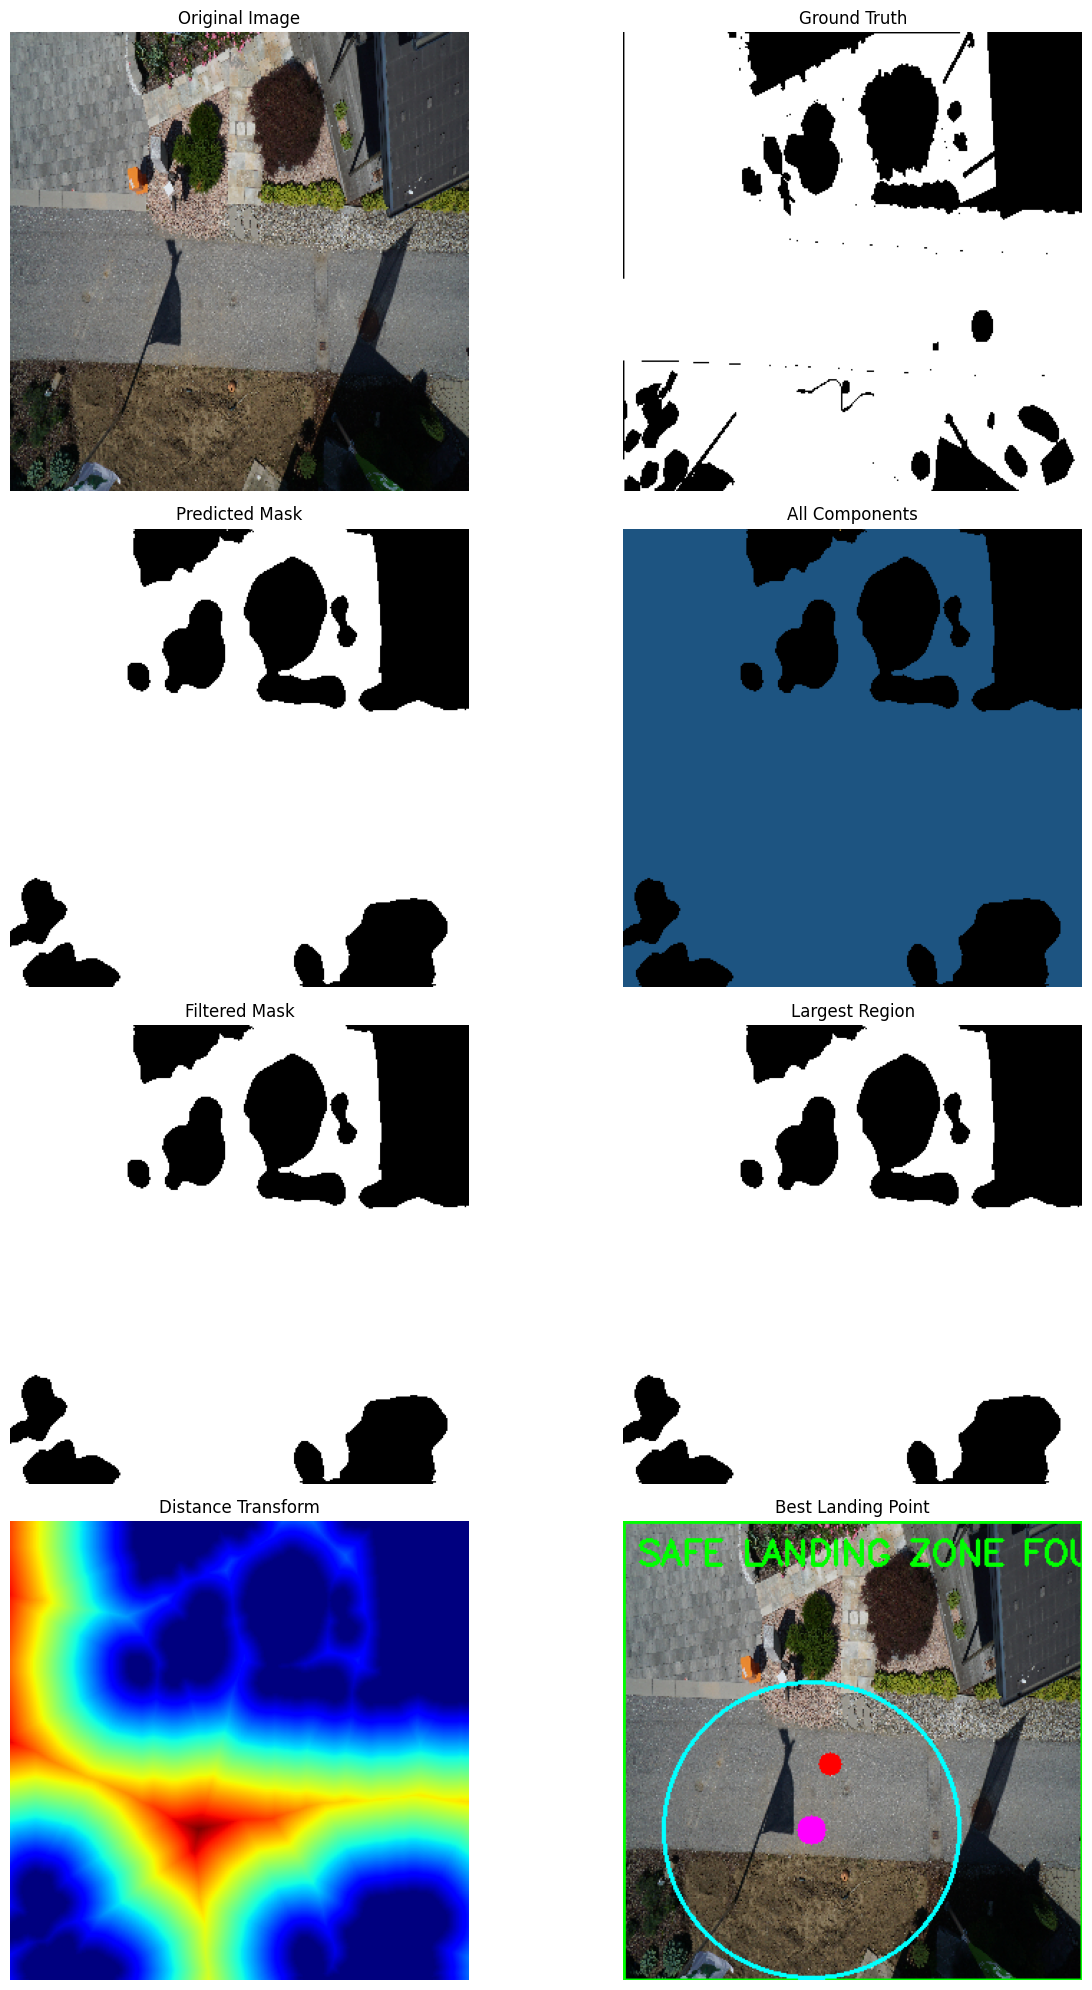



GUIDANCE REPORT
Image Center : (160, 160)
Landing Point : (131, 215)

dx = -29 px
dy = 55 px

Distance = 62.18 px
Heading  = 117.80°

Horizontal Command : MOVE LEFT
Vertical Command   : MOVE BACKWARD

Centered : False
Landing Allowed : True

Current Flight State : GUIDING

FLIGHT CONTROLLER OUTPUT
Flight State : GUIDING
Flight Mode  : GUIDED
vx (Forward speed)         : -0.55 m/s
vy (Left/right speed)        : -0.29 m/s
vz         : 0.00 m/s
Yaw Rate   : 0.00 rad/s

Target X : 131
Target Y : 215

Heading    : 117.80°
Distance   : 62.18 px

Landing Allowed : True


In [ ]:
import cv2
import os
import torch
import random
import numpy as np
import matplotlib.pyplot as plt


# ==============================================================================
# SELECT RANDOM IMAGE
# ==============================================================================

idx = random.randint(0, len(test_dataset)-1)

print(f"\nTesting Image Index = {idx}")

image, mask = test_dataset[idx]

images = image.unsqueeze(0).to(DEVICE)
masks  = mask.unsqueeze(0).to(DEVICE)

# ==============================================================================
# PREDICTION
# ==============================================================================

with torch.no_grad():

    outputs = model(images)

    probs = torch.sigmoid(outputs)

    pred_mask = (probs > 0.5).float()

pred_mask_np = pred_mask[0].squeeze().cpu().numpy().astype(np.uint8)

# ==============================================================================
# PREPARE ORIGINAL IMAGE
# ==============================================================================

img_np = image.permute(1, 2, 0).cpu().numpy()

mean = np.array(IMAGENET_MEAN)
std  = np.array(IMAGENET_STD)

img_np = np.clip(img_np * std + mean, 0, 1)

# ==============================================================================
# CONNECTED COMPONENTS
# ==============================================================================

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    pred_mask_np,
    connectivity=8
)

print("\n" + "="*60)
print(f"Connected Components Found : {num_labels - 1}")
print("="*60)

# ==============================================================================
# COLORED COMPONENTS
# ==============================================================================

colored_labels = np.zeros(
    (labels.shape[0], labels.shape[1], 3),
    dtype=np.uint8
)

rng = np.random.default_rng()

for i in range(1, num_labels):

    color = rng.integers(
        0,
        255,
        size=3,
        dtype=np.uint8
    )

    colored_labels[labels == i] = color

# ==============================================================================
# FILTER REGIONS
# ==============================================================================

MIN_AREA = 5000

valid_regions = []

for i in range(1, num_labels):

    area = stats[i, cv2.CC_STAT_AREA]

    if area < MIN_AREA:
        continue

    valid_regions.append(i)

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]

    cx, cy = centroids[i]

    print(
        f"Region {i} KEPT | "
        f"Area={area} px | "
        f"BBox=({x},{y},{w},{h}) | "
        f"Centroid=({cx:.1f},{cy:.1f})"
    )

print(f"\nValid Regions : {len(valid_regions)}")

# ==============================================================================
# FILTERED MASK
# ==============================================================================

filtered_mask = np.zeros_like(pred_mask_np)

for region_id in valid_regions:
    filtered_mask[labels == region_id] = 1

# ==============================================================================
# DEFAULT VALUES
# ==============================================================================

largest_region = None
largest_region_mask = np.zeros_like(pred_mask_np)
distance_map = np.zeros_like(pred_mask_np, dtype=np.float32)

landing_x = None
landing_y = None

cx = None
cy = None

maxVal = 0.0

landing_allowed = False

guide = None
control = None

# ==============================================================================
# SELECT LARGEST REGION
# ==============================================================================

if len(valid_regions) == 0:

    landing_allowed = False

    state = FlightState.SEARCHING

    print("No valid landing zone detected.")

    guide = {
          "center_x": 160,
          "center_y": 160,
          "landing_x": None,
          "landing_y": None,
          "dx": 0,
          "dy": 0,
          "distance": 0.0,
          "heading": 0.0,
          "horizontal": "HOLD",
          "vertical": "HOLD",
          "centered": False
    }
    control = flight_controller(
        state=state,
        guide=guide,
        landing_allowed=False
    )


else:

    largest_region = max(
        valid_regions,
        key=lambda r: stats[r, cv2.CC_STAT_AREA]
    )

    largest_area = stats[largest_region, cv2.CC_STAT_AREA]

    print("\n" + "="*60)
    print(f"Largest Region = {largest_region}")
    print(f"Area = {largest_area}")
    print("="*60)

    # ==============================================================================
    # LARGEST REGION MASK
    # ==============================================================================

    largest_region_mask = np.zeros_like(pred_mask_np)

    largest_region_mask[labels == largest_region] = 1

    # ==============================================================================
    # DISTANCE TRANSFORM Euclidean Distance Transform
    # ==============================================================================

    distance_map = cv2.distanceTransform(
        largest_region_mask,
        cv2.DIST_L2,
        5
    )

    # ==============================================================================
    # LANDING POINT minMaxLoc
    # ==============================================================================

    minVal, maxVal, minLoc, maxLoc = cv2.minMaxLoc(distance_map)

    landing_x = maxLoc[0]
    landing_y = maxLoc[1]

    cx, cy = centroids[largest_region]

    print("\nBest Landing Point")
    print(f"X = {landing_x}")
    print(f"Y = {landing_y}")
    print(f"Safety Radius = {maxVal:.2f}")

    # ==============================================================================
    # LANDING DECISION
    # ==============================================================================

    MIN_RADIUS = 20 # pixels of free space around the landing point.

    print("\n" + "="*60)
    print("LANDING DECISION")
    print("="*60)

    if maxVal >= MIN_RADIUS:

        landing_allowed = True

        print("✅ LANDING ALLOWED")
        print(f"Safety Radius = {maxVal:.2f} px")
        print(f"Required Radius = {MIN_RADIUS} px")

    else:

        landing_allowed = False

        print("❌ LANDING REJECTED")
        print(f"Safety Radius = {maxVal:.2f} px")
        print(f"Required Radius = {MIN_RADIUS} px")

    # ==============================================================================
    # GUIDANCE
    # ==============================================================================

    guide = guidance_controller(

        landing_x=landing_x,
        landing_y=landing_y,

        #landing_allowed=landing_allowed,

        image_width=320,
        image_height=320,

        tolerance=10
    )

    # ==============================================================================
    # FLIGHT STATE MACHINE
    # ==============================================================================

    state = flight_state_machine.update(

          landing_allowed=landing_allowed,

          centered=guide["centered"]

      )

    # ==============================================================================
    # Control
    # ==============================================================================

    control = flight_controller(

        state=state,

        guide=guide,

        landing_allowed=landing_allowed

    )

# ==============================================================================
# VISUALIZATION
# ==============================================================================

""" landing_vis = (img_np * 255).astype(np.uint8).copy()

 x = stats[largest_region, cv2.CC_STAT_LEFT]
y = stats[largest_region, cv2.CC_STAT_TOP]
w = stats[largest_region, cv2.CC_STAT_WIDTH]
h = stats[largest_region, cv2.CC_STAT_HEIGHT]

cv2.rectangle(
    landing_vis,
    (x, y),
    (x+w, y+h),
    (0,255,0),
    2
)

# centroid = RED

cv2.circle(
    landing_vis,
    (int(cx), int(cy)),
    8,
    (255,0,0),
    -1
)

# safest point = MAGENTA

cv2.circle(
    landing_vis,
    (landing_x, landing_y),
    10,
    (255,0,255),
    -1
)

cv2.putText(
    landing_vis,
    "Landing",
    (landing_x+10, landing_y),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.6,
    (255,255,255),
    2
)"""

"""if landing_allowed:

    text = "LANDING ALLOWED"

else:

    text = "LANDING REJECTED"

cv2.putText(
    landing_vis,
    text,
    (10, 30),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (255,255,255),
    2
)

cv2.circle(
    landing_vis,
    (landing_x, landing_y),
    int(maxVal),
    (0,255,255),
    2
)"""

# ==============================================================================
# VISUALIZATION
# ==============================================================================

landing_vis = (img_np * 255).astype(np.uint8).copy()

# ------------------------------------------------------------------------------
# Draw landing information only if a landing region exists
# ------------------------------------------------------------------------------

if largest_region is not None:

    x = stats[largest_region, cv2.CC_STAT_LEFT]
    y = stats[largest_region, cv2.CC_STAT_TOP]
    w = stats[largest_region, cv2.CC_STAT_WIDTH]
    h = stats[largest_region, cv2.CC_STAT_HEIGHT]

    cv2.rectangle(
        landing_vis,
        (x, y),
        (x + w, y + h),
        (0,255,0),
        2
    )

    # Region centroid
    cv2.circle(
        landing_vis,
        (int(cx), int(cy)),
        8,
        (255,0,0),
        -1
    )

    # Best landing point
    cv2.circle(
        landing_vis,
        (landing_x, landing_y),
        10,
        (255,0,255),
        -1
    )

    # Safe landing radius
    cv2.circle(
        landing_vis,
        (landing_x, landing_y),
        int(maxVal),
        (0,255,255),
        2
    )

# ------------------------------------------------------------------------------
# Status text
# ------------------------------------------------------------------------------

if state == FlightState.SEARCHING:

    text = "SEARCHING FOR LANDING ZONE"
    color = (255,0,0)

elif landing_allowed:

    text = "SAFE LANDING ZONE FOUND"
    color = (0,255,0)

else:

    text = "LANDING NOT SAFE"
    color = (0,0,255)

cv2.putText(
    landing_vis,
    text,
    (10,30),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    color,
    2
)

# ==============================================================================
# DISPLAY
# ==============================================================================

fig, ax = plt.subplots(4, 2, figsize=(14, 20))

ax[0,0].imshow(img_np)
ax[0,0].set_title("Original Image")

ax[0,1].imshow(
    masks[0].squeeze().cpu().numpy(),
    cmap="gray"
)
ax[0,1].set_title("Ground Truth")

ax[1,0].imshow(
    pred_mask_np,
    cmap="gray"
)
ax[1,0].set_title("Predicted Mask")

ax[1,1].imshow(colored_labels)
ax[1,1].set_title("All Components")

ax[2,0].imshow(
    filtered_mask,
    cmap="gray"
)
ax[2,0].set_title("Filtered Mask")

""" ax[2,1].imshow(
    largest_region_mask,
    cmap="gray"
)
ax[2,1].set_title("Largest Region")

ax[3,0].imshow(
    distance_map,
    cmap="jet"
)
ax[3,0].set_title("Distance Transform")"""

if largest_region is None:

    ax[2,1].imshow(
        np.zeros_like(pred_mask_np),
        cmap="gray"
    )
    ax[2,1].set_title("No Landing Region")

    ax[3,0].imshow(
        np.zeros_like(pred_mask_np),
        cmap="gray"
    )
    ax[3,0].set_title("Distance Transform (N/A)")

else:

    ax[2,1].imshow(
        largest_region_mask,
        cmap="gray"
    )
    ax[2,1].set_title("Largest Region")

    ax[3,0].imshow(
        distance_map,
        cmap="jet"
    )
    ax[3,0].set_title("Distance Transform")

ax[3,1].imshow(landing_vis)
ax[3,1].set_title("Best Landing Point")

for row in ax:
    for a in row:
        a.axis("off")

plt.tight_layout()
plt.show()



print("\n")
print("="*60)
print("GUIDANCE REPORT")
print("="*60)

print(f"Image Center : ({guide['center_x']}, {guide['center_y']})")

if landing_x is None:

    print("Landing Point : None")

else:

    print(f"Landing Point : ({landing_x}, {landing_y})")

print()

print(f"dx = {guide['dx']} px")
print(f"dy = {guide['dy']} px")

print()

print(f"Distance = {guide['distance']:.2f} px")

print(f"Heading  = {guide['heading']:.2f}°")

print()

if state == FlightState.SEARCHING:

    print("Horizontal Command : SEARCH")
    print("Vertical Command   : SEARCH")

else:

    print(f"Horizontal Command : {guide['horizontal']}")
    print(f"Vertical Command   : {guide['vertical']}")

print()

print(f"Centered : {guide['centered']}")

print(f"Landing Allowed : {landing_allowed}")

print()

print(f"Current Flight State : {state.value}")

print("="*60)


print()
print("="*60)
print("FLIGHT CONTROLLER OUTPUT")
print("="*60)

print(f"Flight State : {control['state'].value}")
print(f"Flight Mode  : {control['mode']}")

print(f"vx (Forward speed)         : {control['vx']:.2f} m/s")
print(f"vy (Left/right speed)        : {control['vy']:.2f} m/s")
print(f"vz         : {control['vz']:.2f} m/s")
print(f"Yaw Rate   : {control['yaw_rate']:.2f} rad/s")

print()

if control["target_x"] is None:

    print("Target : None")

else:

    print(f"Target X : {control['target_x']}")
    print(f"Target Y : {control['target_y']}")

print()

print(f"Heading    : {control['heading']:.2f}°")
print(f"Distance   : {control['distance']:.2f} px")

print()

print(f"Landing Allowed : {control['landing_allowed']}")

print("="*60)

# Guidance visualisation

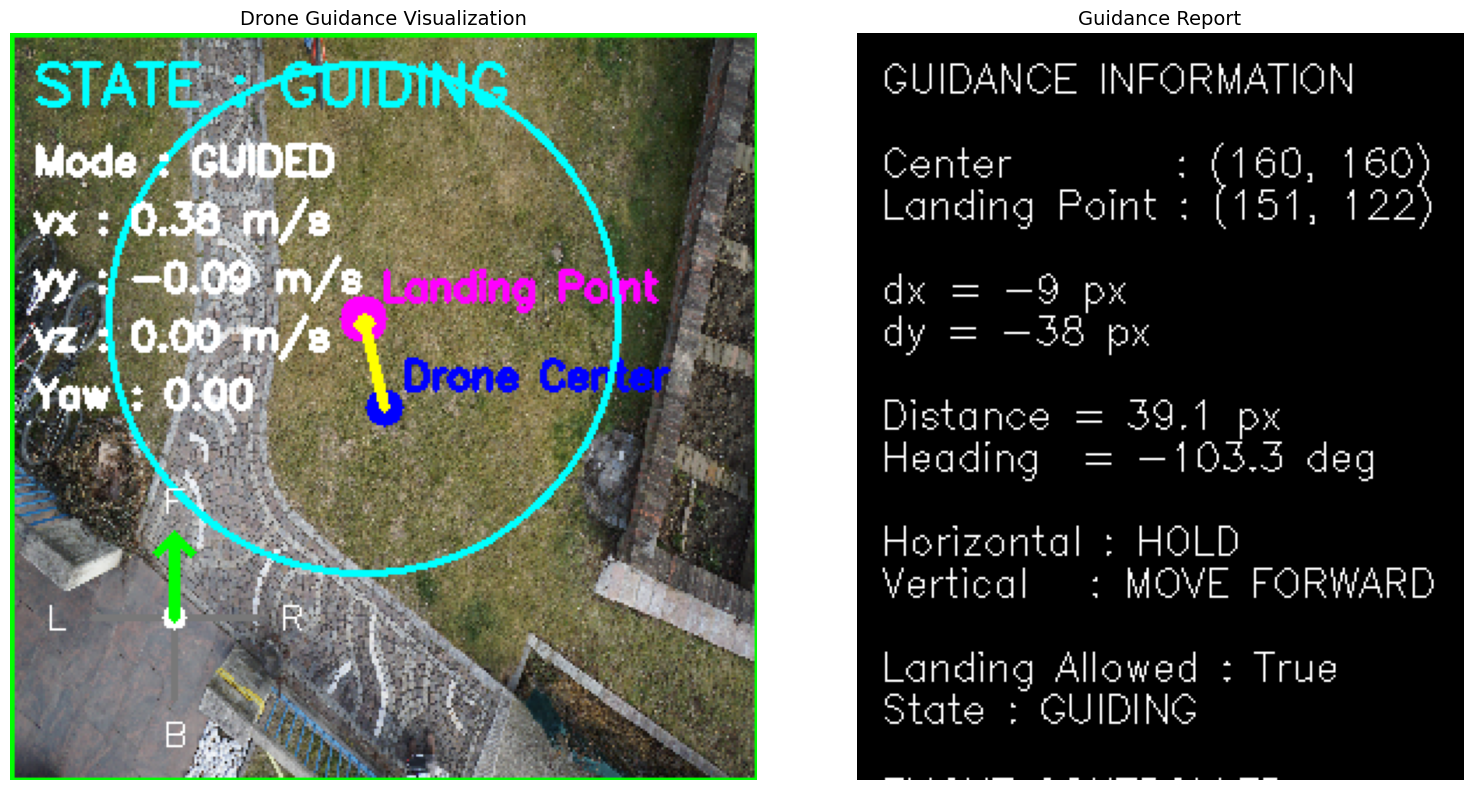

In [ ]:
# ==============================================================================
# GUIDANCE VISUALIZATION
# ==============================================================================

import cv2
import matplotlib.pyplot as plt
import numpy as np

# RGB image
guidance_vis = (img_np * 255).astype(np.uint8).copy()

# ==============================================================================
# DRAW LARGEST LANDING ZONE
# ==============================================================================

x = stats[largest_region, cv2.CC_STAT_LEFT]
y = stats[largest_region, cv2.CC_STAT_TOP]
w = stats[largest_region, cv2.CC_STAT_WIDTH]
h = stats[largest_region, cv2.CC_STAT_HEIGHT]

cv2.rectangle(
    guidance_vis,
    (x, y),
    (x+w, y+h),
    (0,255,0),
    2
)

# ==============================================================================
# IMAGE CENTER (Drone Position)
# ==============================================================================

center_x = guide["center_x"]
center_y = guide["center_y"]

cv2.circle(
    guidance_vis,
    (center_x, center_y),
    8,
    (0,0,255),
    -1
)

cv2.putText(
    guidance_vis,
    "Drone Center",
    (center_x+8, center_y-8),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    (0,0,255),
    2
)

# ==============================================================================
# LANDING TARGET
# ==============================================================================

cv2.circle(
    guidance_vis,
    (landing_x, landing_y),
    10,
    (255,0,255),
    -1
)

cv2.putText(
    guidance_vis,
    "Landing Point",
    (landing_x+8, landing_y-8),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    (255,0,255),
    2
)

# ==============================================================================
# GUIDANCE VECTOR
# ==============================================================================

cv2.arrowedLine(
    guidance_vis,
    (center_x, center_y),
    (landing_x, landing_y),
    (255,255,0),
    3,
    tipLength=0.08
)

# ==============================================================================
# SAFE LANDING RADIUS
# ==============================================================================

cv2.circle(
    guidance_vis,
    (landing_x, landing_y),
    int(maxVal),
    (0,255,255),
    2
)

# ==============================================================================
# DIRECTION HUD
# ==============================================================================

hud_x = 70
hud_y = 250
arrow_len = 35
gray = (120,120,120)
green = (0,255,0)

# ----------------------------
# Draw reference cross
# ----------------------------

cv2.line(
    guidance_vis,
    (hud_x-arrow_len, hud_y),
    (hud_x+arrow_len, hud_y),
    gray,
    2
)

cv2.line(
    guidance_vis,
    (hud_x, hud_y-arrow_len),
    (hud_x, hud_y+arrow_len),
    gray,
    2
)

cv2.circle(
    guidance_vis,
    (hud_x, hud_y),
    5,
    (255,255,255),
    -1
)

# Labels

cv2.putText(guidance_vis, "F", (hud_x-5, hud_y-arrow_len-10),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)

cv2.putText(guidance_vis, "B", (hud_x-5, hud_y+arrow_len+20),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)

cv2.putText(guidance_vis, "L", (hud_x-arrow_len-20, hud_y+5),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)

cv2.putText(guidance_vis, "R", (hud_x+arrow_len+10, hud_y+5),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)

# ==============================================================================
# HORIZONTAL COMMAND
# ==============================================================================

if guide["horizontal"] == "MOVE LEFT":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x, hud_y),
        (hud_x-arrow_len, hud_y),
        green,
        4,
        tipLength=0.3
    )

elif guide["horizontal"] == "MOVE RIGHT":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x, hud_y),
        (hud_x+arrow_len, hud_y),
        green,
        4,
        tipLength=0.3
    )

# ==============================================================================
# VERTICAL COMMAND
# ==============================================================================

if guide["vertical"] == "MOVE FORWARD":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x, hud_y),
        (hud_x, hud_y-arrow_len),
        green,
        4,
        tipLength=0.3
    )

elif guide["vertical"] == "MOVE BACKWARD":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x, hud_y),
        (hud_x, hud_y+arrow_len),
        green,
        4,
        tipLength=0.3
    )

# ==============================================================================
# INFORMATION PANEL
# ==============================================================================

panel = np.zeros((320, 260, 3), dtype=np.uint8)

info = [

    "GUIDANCE INFORMATION",

    "",

    f"Center        : ({center_x}, {center_y})",

    f"Landing Point : ({landing_x}, {landing_y})",

    "",

    f"dx = {guide['dx']} px",

    f"dy = {guide['dy']} px",

    "",

    f"Distance = {guide['distance']:.1f} px",

    f"Heading  = {guide['heading']:.1f} deg",

    "",

    f"Horizontal : {guide['horizontal']}",

    f"Vertical   : {guide['vertical']}",

    "",

    f"Landing Allowed : {landing_allowed}",

    f"State : {state.value}",

    "",
    "FLIGHT CONTROLLER",
    "",

    f"Mode : {control['mode']}",
    f"vx : {control['vx']:.2f} m/s",
    f"vy : {control['vy']:.2f} m/s",
    f"vz : {control['vz']:.2f} m/s",
    f"Yaw : {control['yaw_rate']:.2f}",

]

# ==============================================================================
# STATE COLOR
# ==============================================================================

if state == FlightState.SEARCHING:

    state_color = (0,0,255)          # Red

elif state == FlightState.GUIDING:

    state_color = (0,255,255)        # Yellow

else:

    state_color = (0,255,0)          # Green


# ==============================================================================
# WRITE PANEL
# ==============================================================================

y = 25

for txt in info:

    cv2.putText(
        panel,
        txt,
        (10, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (255,255,255),
        1
    )

    y += 18

# ==============================================================================
# DRAW FLIGHT STATE ON CAMERA VIEW
# ==============================================================================

cv2.putText(
    guidance_vis,
    f"STATE : {state.value}",
    (10,30),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    state_color,
    2
)

# ==============================================================================
# DRAW CONTROLLER OUTPUT ON CAMERA VIEW
# ==============================================================================

cv2.putText(
    guidance_vis,
    f"Mode : {control['mode']}",
    (10,60),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    (255,255,255),
    2
)

cv2.putText(
    guidance_vis,
    f"vx : {control['vx']:.2f} m/s",
    (10,85),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    (255,255,255),
    2
)

cv2.putText(
    guidance_vis,
    f"vy : {control['vy']:.2f} m/s",
    (10,110),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    (255,255,255),
    2
)

cv2.putText(
    guidance_vis,
    f"vz : {control['vz']:.2f} m/s",
    (10,135),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    (255,255,255),
    2
)

cv2.putText(
    guidance_vis,
    f"Yaw : {control['yaw_rate']:.2f}",
    (10,160),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    (255,255,255),
    2
)

# ==============================================================================
# DISPLAY
# ==============================================================================

fig, ax = plt.subplots(1,2, figsize=(16,8))

ax[0].imshow(guidance_vis)
ax[0].set_title("Drone Guidance Visualization", fontsize=14)

ax[1].imshow(panel)
ax[1].set_title("Guidance Report", fontsize=14)

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Guidance visualisation v2

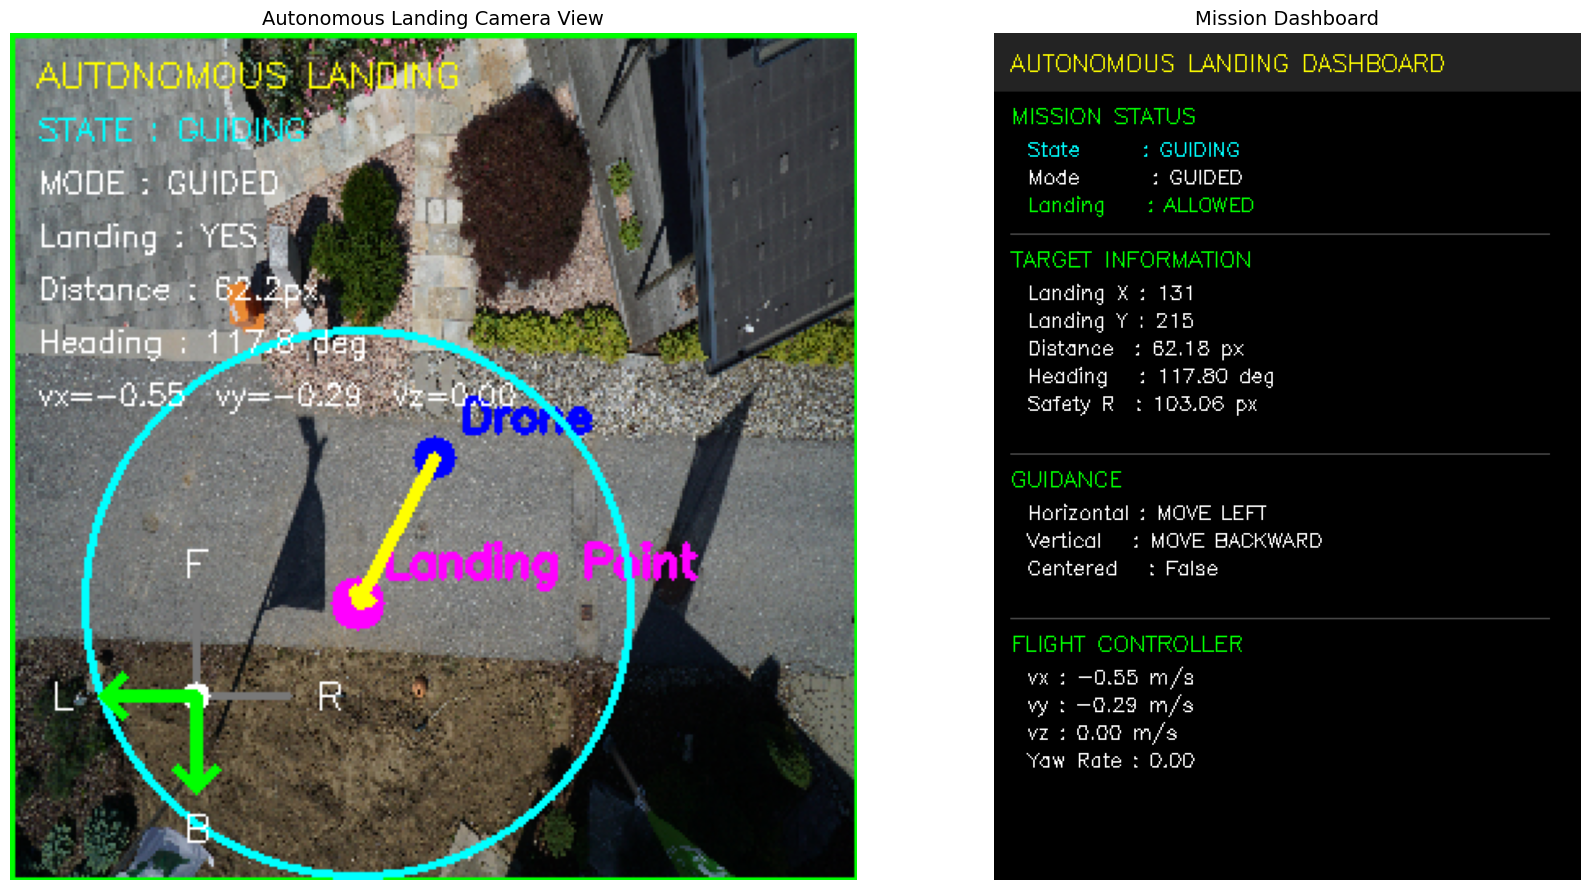

In [ ]:
# ==============================================================================
# GUIDANCE VISUALIZATION (PART 1)
# ==============================================================================

import cv2
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# PREPARE RGB IMAGE
# ==============================================================================

guidance_vis = (img_np * 255).astype(np.uint8).copy()

# ==============================================================================
# COLORS
# ==============================================================================

WHITE   = (255,255,255)
GREEN   = (0,255,0)
RED     = (0,0,255)
YELLOW  = (0,255,255)
MAGENTA = (255,0,255)
CYAN    = (255,255,0)
GRAY    = (120,120,120)

# ==============================================================================
# DRAW LARGEST LANDING ZONE
# ==============================================================================

x = stats[largest_region, cv2.CC_STAT_LEFT]
y = stats[largest_region, cv2.CC_STAT_TOP]
w = stats[largest_region, cv2.CC_STAT_WIDTH]
h = stats[largest_region, cv2.CC_STAT_HEIGHT]

cv2.rectangle(
    guidance_vis,
    (x,y),
    (x+w,y+h),
    GREEN,
    2
)

# ==============================================================================
# DRONE CENTER
# ==============================================================================

center_x = guide["center_x"]
center_y = guide["center_y"]

cv2.circle(
    guidance_vis,
    (center_x,center_y),
    8,
    RED,
    -1
)

cv2.putText(
    guidance_vis,
    "Drone",
    (center_x+10,center_y-10),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    RED,
    2
)

# ==============================================================================
# LANDING TARGET
# ==============================================================================

cv2.circle(
    guidance_vis,
    (landing_x,landing_y),
    10,
    MAGENTA,
    -1
)

cv2.putText(
    guidance_vis,
    "Landing Point",
    (landing_x+10,landing_y-10),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.55,
    MAGENTA,
    2
)

# ==============================================================================
# GUIDANCE VECTOR
# ==============================================================================

cv2.arrowedLine(
    guidance_vis,
    (center_x,center_y),
    (landing_x,landing_y),
    CYAN,
    3,
    tipLength=0.08
)

# ==============================================================================
# SAFE LANDING CIRCLE
# ==============================================================================

cv2.circle(
    guidance_vis,
    (landing_x,landing_y),
    int(maxVal),
    YELLOW,
    2
)

# ==============================================================================
# DIRECTION HUD
# ==============================================================================

hud_x = 70
hud_y = 250
arrow_len = 35

# cross

cv2.line(
    guidance_vis,
    (hud_x-arrow_len,hud_y),
    (hud_x+arrow_len,hud_y),
    GRAY,
    2
)

cv2.line(
    guidance_vis,
    (hud_x,hud_y-arrow_len),
    (hud_x,hud_y+arrow_len),
    GRAY,
    2
)

cv2.circle(
    guidance_vis,
    (hud_x,hud_y),
    5,
    WHITE,
    -1
)

# labels

cv2.putText(guidance_vis,"F",
            (hud_x-5,hud_y-arrow_len-10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            WHITE,
            1)

cv2.putText(guidance_vis,"B",
            (hud_x-5,hud_y+arrow_len+20),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            WHITE,
            1)

cv2.putText(guidance_vis,"L",
            (hud_x-arrow_len-20,hud_y+5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            WHITE,
            1)

cv2.putText(guidance_vis,"R",
            (hud_x+arrow_len+10,hud_y+5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            WHITE,
            1)

# ==============================================================================
# HORIZONTAL COMMAND
# ==============================================================================

if guide["horizontal"] == "MOVE LEFT":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x,hud_y),
        (hud_x-arrow_len,hud_y),
        GREEN,
        4,
        tipLength=0.30
    )

elif guide["horizontal"] == "MOVE RIGHT":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x,hud_y),
        (hud_x+arrow_len,hud_y),
        GREEN,
        4,
        tipLength=0.30
    )

# ==============================================================================
# VERTICAL COMMAND
# ==============================================================================

if guide["vertical"] == "MOVE FORWARD":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x,hud_y),
        (hud_x,hud_y-arrow_len),
        GREEN,
        4,
        tipLength=0.30
    )

elif guide["vertical"] == "MOVE BACKWARD":

    cv2.arrowedLine(
        guidance_vis,
        (hud_x,hud_y),
        (hud_x,hud_y+arrow_len),
        GREEN,
        4,
        tipLength=0.30
    )

# ==============================================================================
# FLIGHT STATE COLOR
# ==============================================================================

if state == FlightState.SEARCHING:

    state_color = RED

elif state == FlightState.GUIDING:

    state_color = YELLOW

else:

    state_color = GREEN

# ==============================================================================
# CAMERA HUD
# ==============================================================================

cv2.putText(
    guidance_vis,
    "AUTONOMOUS LANDING",
    (10,20),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.45,   # smaller font
    CYAN,
    1       # thinner text
)

cv2.putText(
    guidance_vis,
    f"STATE : {state.value}",
    (10,40),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.40,
    state_color,
    1
)

cv2.putText(
    guidance_vis,
    f"MODE : {control['mode']}",
    (10,60),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.38,
    WHITE,
    1
)

cv2.putText(
    guidance_vis,
    f"Landing : {'YES' if landing_allowed else 'NO'}",
    (10,80),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.38,
    WHITE,
    1
)

cv2.putText(
    guidance_vis,
    f"Distance : {guide['distance']:.1f}px",
    (10,100),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.38,
    WHITE,
    1
)

cv2.putText(
    guidance_vis,
    f"Heading : {guide['heading']:.1f} deg",
    (10,120),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.38,
    WHITE,
    1
)

cv2.putText(
    guidance_vis,
    f"vx={control['vx']:.2f}  vy={control['vy']:.2f}  vz={control['vz']:.2f}",
    (10,140),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.36,
    WHITE,
    1
)

# ==============================================================================
# PROFESSIONAL INFORMATION PANEL
# ==============================================================================

panel = np.zeros((520, 360, 3), dtype=np.uint8)

WHITE   = (255,255,255)
GREEN   = (0,255,0)
RED     = (0,0,255)
YELLOW  = (0,255,255)
CYAN    = (255,255,0)
GRAY    = (70,70,70)

# ==============================================================================
# TITLE
# ==============================================================================

cv2.rectangle(panel, (0,0), (360,35), (35,35,35), -1)

cv2.putText(
    panel,
    "AUTONOMOUS LANDING DASHBOARD",
    (10,23),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.48,   # was 0.72
    CYAN,
    1        # was 2
)

# ==============================================================================
# MISSION STATUS
# ==============================================================================

y = 55

cv2.putText(panel, "MISSION STATUS",
            (10,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,   # was 0.60
            GREEN,
            1)

y += 20

cv2.putText(panel,
            f"State      : {state.value}",
            (20,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.40,   # was 0.55
            state_color,
            1)

y += 17

cv2.putText(panel,
            f"Mode       : {control['mode']}",
            (20,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.40,
            WHITE,
            1)

y += 17

cv2.putText(panel,
            f"Landing    : {landing_status}",
            (20,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.40,
            landing_color,
            1)

# ==============================================================================
# SEPARATOR
# ==============================================================================

y += 14
cv2.line(panel, (10,y), (340,y), GRAY, 1)

# ==============================================================================
# TARGET INFORMATION
# ==============================================================================

y += 20

cv2.putText(panel,
            "TARGET INFORMATION",
            (10,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            GREEN,
            1)

y += 20

for text in [
    f"Landing X : {landing_x}",
    f"Landing Y : {landing_y}",
    f"Distance  : {guide['distance']:.2f} px",
    f"Heading   : {guide['heading']:.2f} deg",
    f"Safety R  : {maxVal:.2f} px",
]:
    cv2.putText(panel, text,
                (20,y),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.40,
                WHITE,
                1)
    y += 17

# ==============================================================================
# SEPARATOR
# ==============================================================================

y += 10
cv2.line(panel, (10,y), (340,y), GRAY, 1)

# ==============================================================================
# GUIDANCE
# ==============================================================================

y += 20

cv2.putText(panel,
            "GUIDANCE",
            (10,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            GREEN,
            1)

y += 20

for text in [
    f"Horizontal : {guide['horizontal']}",
    f"Vertical   : {guide['vertical']}",
    f"Centered   : {guide['centered']}",
]:
    cv2.putText(panel, text,
                (20,y),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.40,
                WHITE,
                1)
    y += 17

# ==============================================================================
# SEPARATOR
# ==============================================================================

y += 10
cv2.line(panel, (10,y), (340,y), GRAY, 1)

# ==============================================================================
# FLIGHT CONTROLLER
# ==============================================================================

y += 20

cv2.putText(panel,
            "FLIGHT CONTROLLER",
            (10,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            GREEN,
            1)

y += 20

for text in [
    f"vx : {control['vx']:.2f} m/s",
    f"vy : {control['vy']:.2f} m/s",
    f"vz : {control['vz']:.2f} m/s",
    f"Yaw Rate : {control['yaw_rate']:.2f}",
]:
    cv2.putText(panel, text,
                (20,y),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.40,
                WHITE,
                1)
    y += 17

# ==============================================================================
# DISPLAY
# ==============================================================================

fig, ax = plt.subplots(1,2, figsize=(18,9))

ax[0].imshow(guidance_vis)
ax[0].set_title("Autonomous Landing Camera View", fontsize=14)

ax[1].imshow(panel)
ax[1].set_title("Mission Dashboard", fontsize=14)

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()